# Pedestrian crossing: LLM car with V2X intention (version 7)

Version 6 showed that V2X intention makes the RL car safer: 0.53% collisions against 1.40% without V2X (h = 0.2, mean of 5 runs). This notebook asks whether a free open LLM can drive the same car with the same V2X information.

| Role | What it does |
|---|---|
| Pedestrian | Unchanged from version 6. |
| RSU | Unchanged from version 6. It sees the pedestrian, predicts intention and broadcasts every 0.1 s. |
| Car | An instruction-tuned LLM replaces the PPO policy: Qwen2.5-7B-Instruct, 4-bit, Apache 2.0 licence. It reads the same information as the PPO car with V2X, written as text, and chooses go, keep speed or brake. The same safety floor is re-checked every 0.1 s. |

What stays the same as version 6:
- The environment code, the intention predictor and the 2,000 test scenarios (seeds 10,000+). Cell S7 checks that this notebook reproduces the version 6 outcomes exactly.
- The information. The LLM gets what the PPO car's 11 inputs contain. Times and distances in the text are computed from them. The PPO-LSTM remembers earlier inputs and a single LLM call does not, so the text also gives the pedestrian estimate 1 s earlier and the car's last action.

What is new:

| # | Item | Choice |
|---|---|---|
| 1 | Training | None (zero-shot). The instructions describe the road, the actions, the RSU message and the goal. As in the PPO reward, one collision counts as worse than 500 s of delay. |
| 2 | Answer | One forward pass per call. The car takes the most probable of the three words. No text is generated, so the choice is deterministic and needs no parsing. |
| 3 | Response time | The car asks at most every 0.3 s and keeps its previous action until the answer arrives. The answer takes effect at the next 0.1 s control step after it is ready. Two conditions run on the same scenarios: instant answers (decision quality alone) and the response time measured on this GPU (what a deployed car would get). |
| 4 | When the LLM is asked | Only while a pedestrian who has not finished crossing is known. Otherwise the car cruises. |
| 5 | Speed-ups | Many scenarios run in step, so calls are batched. The fixed instructions are encoded once and reused. Identical situations reuse the stored answer. None of these changes a decision; a self-test checks the reuse of the instructions. |

Comparisons, paired on the same scenarios: car alone, the calibrated rule, perfect intention, PPO without V2X and PPO with V2X. The version 6 results are read from Drive, so version 6 must have finished.

Order and time:
- Runtime: GPU (a free T4 is enough). Cells A and V hold the version 6 code. Cell P reads the version 6 results. Cell S7 runs checks on the CPU (a few minutes).
- Cell M downloads the model (about 15 GB, a few minutes the first time). It then runs a self-test, shows the LLM's first choices next to the rule's and measures the response time. It stops if the model does not answer in the expected format. Run the cells up to Cell M first and check its output before the long run.
- Cell T runs 2,000 scenarios in each condition and prints the time left after every 100. Results are saved to Drive after every chunk. If the session stops, run all cells again: Cell T continues where it stopped.
- Cell R prints the tables and paired tests and draws the plots. It uses the scenarios finished so far.
- Cell X (optional) tests fixed response times of 0.3, 0.6 and 1.0 s.


Code of the paper *Insight Before Sight* (IEEE T-ITS). The prompts in this notebook are the exact prompts of the paper's runs. Results are in `reproduce/data/`.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%pip install -q -U bitsandbytes>=0.46.1 accelerate

Mounted at /content/drive


## Base code (versions 3–5)
Unchanged. Environment, recurrent PPO and evaluation helpers.

In [2]:
# ===== CELL A1: setup
# ============================================================
# Pedestrian crossing with V2X-communicated inferred intention and hesitation
# Recurrent PPO (LSTM). Corrected version.
#
# Every change from the previous notebook is marked "FIX n", with n matching the
# list of mistakes. Observation stays 14-D and there are still 4 actions:
#   obs = [xv, yv, sv, xp, yp, sp, xc, yc, ttc, I_v2x, gx_v2x, gy_v2x, H_v2x, q_v2x]  (now scaled, FIX 17)
#   actions: 0 = keep speed, 1 = brake, 2 = dodge right, 3 = dodge left, 4 = go (regain cruise speed; FIX 4)
# ============================================================
import os, math, json, hashlib, time
from dataclasses import dataclass, asdict, field
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.distributions import Categorical
import gymnasium as gym
from gymnasium import spaces

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch device:", device)


@dataclass
class EnvConfig:
    # time and geometry
    dt: float = 0.1                  # FIX 2: 0.1 s steps (was 1 time unit per step, 1-2 decisions per episode)
    max_steps: int = 300             # 30 s
    action_repeat: int = 3           # one decision every 0.3 s; physics, V2X and collision checks every 0.1 s
    w: float = 2.0                   # lane width (conflict strip is xc +/- w/2)
    l: float = 4.0                   # car length
    car_w: float = 1.8               # car width, used by the collision test (FIX 9)
    ped_r: float = 0.4               # pedestrian radius, used by the collision test (FIX 9)
    near_miss: float = 3.0           # your 3 m radius, now a near-miss margin
    xc: float = 45.0                 # FIX 18: fixed values written as constants (randint(45, 46) always gave 45)
    yc: float = 70.0
    xv0: float = 45.0
    yv0: tuple = (36.0, 44.0)        # car start (centre); front is 24-32 m from the crosswalk
    # car
    v_cruise: tuple = (6.5, 8.5)     # m/s, drawn per episode
    a_go: float = 2.0                # FIX 4: new action 4 "go" regains cruise speed at 2 m/s^2
    a_brake: float = 2.8             # your 2.8, now m/s^2 (FIX 3: decisions start early enough to stop)
    a_dodge: float = 3.0
    v_dodge_min: float = 2.0
    lat_speed: float = 2.0           # m/s sideways while dodging
    road_half: float = 3.0           # road spans xc +/- 3
    # pedestrian
    xp0: tuple = (41.0, 74.0)
    sp: tuple = (1.8, 2.2)
    band: float = 3.0                # hesitation happens within xc +/- band
    pre_roll: float = 2.0            # FIX 20: seconds of pedestrian motion seen by V2X before the episode starts
    # pedestrian model (version 5). "coinflip" reproduces versions 3 and 4 exactly.
    ped_model: str = "coinflip"      # "coinflip": a fresh random move every second near the road
                                     # "gap": gap acceptance; the pedestrian crosses when the car leaves enough time
    crit_gap: tuple = (1.5, 5.0)     # gap: each pedestrian's critical gap (s), drawn once per episode
    judge_noise: float = 0.3         # gap: relative error when the pedestrian judges the car's arrival time
    gap_margin: float = 1.0          # gap: within +/- this of the critical gap the decision is unclear
    curb_offset: float = 0.3         # gap: the pedestrian waits 0.3 m outside the road edge
    recheck: float = 0.5             # gap: a waiting pedestrian looks again every 0.5 s
    hes_step: tuple = (0.5, 1.5)     # gap: a hesitating pedestrian steps out for 0.5-1.5 s (1-3 m) ...
    hes_stop: float = 0.6            # ... then stands for 0.6 s before deciding again
    yield_speed: float = 1.0         # gap: a car slower than this (m/s) is seen as giving way
    p_distracted: float = 0.15       # gap: share of pedestrians who do not look and walk straight across
    p_interact: float = 0.7          # gap: share of episodes in which the pedestrian reaches the curb near the car's arrival
    meet_window: tuple = (-1.0, 5.0) # gap: in those episodes, the pedestrian reaches the curb 1 s after to 5 s before the car would
    hes_period: float = 1.0          # FIX 1: a new move is drawn every 1 s (your original step length)
    # partial observability of pedestrian speed (unchanged)
    po_zone: float = 12.0
    sp_drop: float = 0.9
    sp_noise_far: float = 0.05
    sp_noise_near: float = 0.50
    # limited sensing (version 4). "full" reproduces version 3 exactly, including the checkpoint folder name.
    ego_sensing: str = "full"        # "full", or "occluded": parked cars hide a pedestrian who is off the road
    occlusion_gap: float = 12.0      # occluded: a hidden pedestrian becomes visible when the car front is this close (m)
    ego_pos_noise: float = 0.3       # occluded: std of the car's own pedestrian position estimate (m)
    # inference window (FIX 6: thresholds now in m/s)
    win: int = 10                    # 1 s of history
    stop_thr: float = 0.15
    flip_thr: float = 0.10
    # V2X channel
    v2x_delay: tuple = (0, 1)        # steps (0-100 ms)
    v2x_loss: float = 0.01
    v2x_age_cap: int = 10            # 1 s
    noise_I: float = 0.05
    noise_g: float = 0.08
    noise_H: float = 0.07
    noise_conf: float = 0.05
    # reward, computed from the true state only (FIX 5)
    r_collision: float = -100.0
    r_success: float = 20.0          # FIX 7: paid when the car has passed, checked after the move
    r_time: float = -0.1             # per step (1 per second of waiting)
    r_near: float = -1.0             # per step, scaled by (1 - d / near_miss) while the pedestrian is on the road
    r_brake: float = -0.01           # comfort
    r_dodge: float = -0.05
    r_slow: float = -0.05            # per 0.1 s, times (1 - v / v_cruise), only when the true state shows no conflict: waiting without a reason
    r_ghost_brake: float = 0.0       # optional, per 0.1 s: braking when the true state shows no conflict (off by default; -0.2 made the car too bold)
    r_timeout: float = -20.0

    def key(self):
        d = asdict(self)
        if d.get("ego_sensing", "full") == "full":     # full sensing keeps the version-3 key, so those checkpoints are reused
            for k in ("ego_sensing", "occlusion_gap", "ego_pos_noise"):
                d.pop(k, None)
        if d.get("ped_model", "coinflip") == "coinflip":   # the coin-flip pedestrian keeps the version-3/4 key
            for k in ("ped_model", "crit_gap", "judge_noise", "gap_margin", "curb_offset", "recheck", "hes_step", "hes_stop", "yield_speed",
                      "p_distracted", "p_interact", "meet_window"):
                d.pop(k, None)
        return hashlib.md5(json.dumps(d, sort_keys=True).encode()).hexdigest()[:8]


PyTorch device: cuda


In [3]:
# ===== CELL A2: environment
class PedestrianCrossingEnv(gym.Env):
    """Car drives north on x = xc toward a crosswalk at y = yc. A pedestrian crosses from right to left on y = yc.

    Changes from the previous version, by mistake number:
      1  hesitation probabilities: forward 1-h, stand h/2, back h/2
      2  physics every 0.1 s, a decision every 0.3 s from the start
      3  braking starts early enough to stop
      4  action 0 regains cruise speed, so a car that yielded can drive on
      5  reward uses the true state; V2X appears only in the observation
      6  confidence q no longer drops when the pedestrian stands still
      7  success reward checked after the move
      8  "future position" projection removed
      9  collision tested on the car footprint after each 0.1 s move
      15 message age grows by one per step
      16 ttc is time for the car front to reach the crosswalk, capped at 10 s
      17 observation scaled to about [-1, 1]
      18 constants written as constants
      20 the inference is warm when the episode starts
    """
    metadata = {"render_modes": []}

    def __init__(self, hesitation_prob=0.2, enable_v2x=True, cfg: EnvConfig = None):
        super().__init__()
        self.cfg = cfg or EnvConfig()
        self.h = float(hesitation_prob)
        self.enable_v2x = bool(enable_v2x)
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(14,), dtype=np.float32)
        self.action_space = spaces.Discrete(5)   # FIX 4: action 4 = go

    # ---------- pedestrian ----------
    def _ped_move(self):
        if self.cfg.ped_model == "gap":
            return self._ped_move_gap()
        c, rng = self.cfg, self.ped_rng       # scenario stream: the same for every policy, ON or OFF
        if abs(self.xp - c.xc) <= c.band:
            if self.hes_timer <= 0:
                # FIX 1: was p=[h/2, 1-h, h/2] for [-1, 0, +1], so h = 0 meant "stand still forever"
                self.ped_dir = int(rng.choice([-1, 0, 1], p=[1.0 - self.h, self.h / 2, self.h / 2]))
                self.hes_timer = int(round(c.hes_period / c.dt))
            self.hes_timer -= 1
        else:
            self.ped_dir, self.hes_timer = -1, 0
        self.xp += self.ped_dir * self.sp * c.dt

    # ---------- gap-acceptance pedestrian (version 5) ----------
    def _car_arrival(self):
        """Seconds until the car front reaches the crosswalk, as the pedestrian judges it from the car's
        current speed. 0 if the car is on the crosswalk, infinite once it has passed or when it is giving way."""
        c = self.cfg
        gap = self._front_gap()
        if self.yv - c.l / 2 > c.yc + c.ped_r:          # car has passed
            return float("inf")
        if gap <= 0:                                     # car is on the crosswalk
            return 0.0
        if self.sv < c.yield_speed:                      # car (almost) stopped before the crosswalk: giving way
            return float("inf")
        return gap / self.sv

    def _ped_decide(self, stepped_out=False):
        c = self.cfg
        t_arr, g = self._car_arrival(), self.crit_gap
        if np.isfinite(t_arr):                           # people misjudge how soon a car arrives
            t_arr = max(0.0, t_arr * (1.0 + self.ped_rng.normal(0, c.judge_noise)))
        if t_arr >= g + c.gap_margin:
            choice = "cross"
        elif t_arr <= g - c.gap_margin:
            choice = "wait"
        elif self.ped_rng.random() < self.h:             # unclear gap: hesitate with probability h
            choice = "hesitate"
        else:
            choice = "cross" if t_arr >= g else "wait"
        if choice == "cross":
            self.ped_state = "cross"
        elif choice == "wait":
            self.ped_state, self.ped_timer = ("back", 0.0) if stepped_out else ("wait", c.recheck)
        elif stepped_out:                                # already stepped out: stand again
            self.ped_state, self.ped_timer = "hes_stop", c.hes_stop
        else:
            self.ped_state, self.ped_timer = "hes_step", float(self.ped_rng.uniform(*c.hes_step))

    def _ped_move_gap(self):
        c, dt = self.cfg, self.cfg.dt
        curb = c.xc + c.road_half + c.curb_offset
        st = self.ped_state
        if st == "approach":
            self.xp -= self.sp * dt
            if self.xp <= curb:
                if self.distracted:                      # does not look: keeps walking
                    self.ped_state = "cross"
                else:
                    self.xp = curb
                    self._ped_decide()
        elif st == "wait":
            self.ped_timer -= dt
            if self.ped_timer <= 1e-9:
                self._ped_decide()
        elif st == "hes_step":
            self.xp -= self.sp * dt
            self.ped_timer -= dt
            if self.ped_timer <= 1e-9:
                self.ped_state, self.ped_timer = "hes_stop", c.hes_stop
        elif st == "hes_stop":
            self.ped_timer -= dt
            if self.ped_timer <= 1e-9:
                self._ped_decide(stepped_out=True)
        elif st == "back":
            self.xp += self.sp * dt
            if self.xp >= curb:
                self.xp, self.ped_state, self.ped_timer = curb, "wait", c.recheck
        else:                                            # cross
            self.xp -= self.sp * dt

    # ---------- inference from motion ----------
    def _reset_inference(self):
        n = self.cfg.win
        self.I_smooth = 0.0
        self.vx_hist, self.vy_hist, self.spd_hist = deque(maxlen=n), deque(maxlen=n), deque(maxlen=n)
        self.sign_hist, self.band_hist = deque(maxlen=n), deque(maxlen=n)
        self.prev_xp, self.prev_yp = self.xp, self.yp

    def _update_inference(self):
        c = self.cfg
        vx = (self.xp - self.prev_xp) / c.dt          # FIX 6: velocities in m/s, so thresholds keep their meaning at any dt
        vy = (self.yp - self.prev_yp) / c.dt
        self.prev_xp, self.prev_yp = self.xp, self.yp
        self.vx_hist.append(vx); self.vy_hist.append(vy); self.spd_hist.append(math.hypot(vx, vy))
        self.sign_hist.append(int(np.sign(vx)) if abs(vx) > c.flip_thr else 0)
        self.band_hist.append(int(abs(self.xp - c.xc) <= c.band))

    def _infer(self):
        c = self.cfg
        if len(self.spd_hist) < 2:
            return 0.0, 0.0, 0.0, 0.0, 0.0
        spd, vx, vy = np.asarray(self.spd_hist), np.asarray(self.vx_hist), np.asarray(self.vy_hist)
        mx, my = float(vx.mean()), float(vy.mean())
        mn = math.hypot(mx, my)
        gx, gy = (mx / mn, my / mn) if mn >= c.stop_thr else (0.0, 0.0)
        stop_ratio = float(np.mean(spd < c.stop_thr))
        s = [v for v in self.sign_hist if v != 0]
        flip_rate = sum(a != b for a, b in zip(s[:-1], s[1:])) / (len(s) - 1) if len(s) > 1 else 0.0
        band_ratio = float(np.mean(self.band_hist))
        H = float(np.clip((0.6 * stop_ratio + 0.4 * flip_rate) * (0.7 + 0.6 * band_ratio), 0, 1))
        toward = float(np.mean(vx < -c.flip_thr))
        speed_score = float(np.clip(spd.mean() / (c.stop_thr * 4), 0, 1))
        raw_I = float(np.clip((0.55 * toward + 0.45 * speed_score) * (1 - 0.8 * H), 0, 1))
        self.I_smooth = 0.85 * self.I_smooth + 0.15 * raw_I
        # FIX 6: confidence reflects how much history the estimate rests on, not how fast the pedestrian walks.
        # (Before, q fell for a pedestrian standing in the lane, which then looked safe.)
        conf = len(self.spd_hist) / c.win
        return float(self.I_smooth), gx, gy, H, conf

    # ---------- V2X ----------
    def _v2x_send(self, I, gx, gy, H, conf):
        c, rng = self.cfg, self.noise_rng     # noise stream: V2X loss, delay and noise
        if not self.enable_v2x or rng.random() < c.v2x_loss:
            return
        msg = (float(np.clip(I + rng.normal(0, c.noise_I), 0, 1)),
               float(np.clip(gx + rng.normal(0, c.noise_g), -1, 1)),
               float(np.clip(gy + rng.normal(0, c.noise_g), -1, 1)),
               float(np.clip(H + rng.normal(0, c.noise_H), 0, 1)),
               float(np.clip(conf + rng.normal(0, c.noise_conf), 0, 1)))
        delay = int(rng.integers(c.v2x_delay[0], c.v2x_delay[1] + 1))
        self.queue.append((self.t + delay, msg))

    def _v2x_deliver(self):
        # FIX 15: called once per step, so the age grows by exactly one per step without a new message
        arrived = False
        while self.queue and self.queue[0][0] <= self.t:
            _, self.msg = self.queue.popleft()
            self.age, arrived = 0, True
        if not arrived:
            self.age = min(self.age + 1, 255)

    def _v2x_q(self):
        if not self.enable_v2x:
            return 0.0
        return float(np.clip(self.msg[4] * math.exp(-3.0 * min(self.age / self.cfg.v2x_age_cap, 1.0)), 0, 1))

    # ---------- geometry ----------
    def _visible(self):
        """Can the car's own sensors see the pedestrian? Always, with full sensing. With occlusion, parked cars
        hide a pedestrian who is off the road until the car front is within occlusion_gap of the crosswalk."""
        c = self.cfg
        if c.ego_sensing == "full":
            return True
        return abs(self.xp - c.xc) <= c.road_half or self._front_gap() <= c.occlusion_gap

    def _conflict(self, perceived=False):
        """True state: the pedestrian is on the road, or will reach it before the car could pass.
        perceived=True (used by the shield): a pedestrian the car cannot see is not known."""
        c = self.cfg
        if perceived and not self._visible():
            return False
        gap = self._front_gap()
        if gap < -(c.l + c.ped_r):                      # car already past the crosswalk
            return False
        if abs(self.xp - c.xc) <= c.road_half:          # pedestrian on the road
            return True
        if self.xp < c.xc:                              # pedestrian has crossed
            return False
        t_pass = (max(gap, 0.0) + c.l + c.ped_r) / max(self.sv, 0.5 * self.v_cruise)
        t_ped = (self.xp - (c.xc + c.road_half)) / max(self.sp, 0.1)
        return t_ped <= t_pass + 1.0

    def _front_gap(self):
        return self.cfg.yc - (self.yv + self.cfg.l / 2)          # metres from car front to crosswalk line

    def _collision(self):
        # FIX 8, 9: footprint test after every 0.1 s move (car moves at most 0.85 m per step)
        c = self.cfg
        return (abs(self.xp - self.xv) <= c.car_w / 2 + c.ped_r) and (abs(self.yp - self.yv) <= c.l / 2 + c.ped_r)

    def _sp_observed(self):
        c, rng = self.cfg, self.noise_rng
        if self._front_gap() <= c.po_zone:
            if rng.random() < c.sp_drop:
                return 0.0
            return max(0.0, self.sp * (1 + rng.normal(0, c.sp_noise_near)))
        return max(0.0, self.sp * (1 + rng.normal(0, c.sp_noise_far)))

    def _obs(self):
        c = self.cfg
        ttc = min(max(self._front_gap(), 0.0) / max(self.sv, 0.5), 10.0)    # FIX 16
        I, gx, gy, H, _ = self.msg if self.enable_v2x else (0.0, 0.0, 0.0, 0.0, 0.0)
        if c.ego_sensing == "full":
            o = np.array([                                                      # FIX 17: scaled inputs
                (self.xv - c.xc) / c.road_half, (self.yv - c.yc) / 30.0, self.sv / 8.5,
                (self.xp - c.xc) / 30.0, (self.yp - c.yc) / 5.0, self._sp_observed() / 2.2,
                c.xc / 100.0, c.yc / 100.0, ttc / 10.0,
                I, gx, gy, H, self._v2x_q()], dtype=np.float32)
            return o
        # occluded: slots 6 and 7 (constants above) carry "pedestrian visible" and "time since last seen"
        if self._visible():
            xp_m = self.xp + self.noise_rng.normal(0, c.ego_pos_noise)
            ped = ((xp_m - c.xc) / 30.0, (self.yp - c.yc) / 5.0, self._sp_observed() / 2.2)
            vis = 1.0
        else:
            ped, vis = (0.0, 0.0, 0.0), 0.0
        o = np.array([
            (self.xv - c.xc) / c.road_half, (self.yv - c.yc) / 30.0, self.sv / 8.5,
            *ped, vis, min(self.since_seen, 5.0) / 5.0, ttc / 10.0,
            I, gx, gy, H, self._v2x_q()], dtype=np.float32)
        return o

    # ---------- gym API ----------
    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)          # per-episode seeds give every policy the same scenarios in evaluation (FIX 13)
        c, rng = self.cfg, self.np_random
        self.t = 0
        self.xv, self.yv = c.xv0, float(rng.uniform(*c.yv0))
        self.v_cruise = float(rng.uniform(*c.v_cruise)); self.sv = self.v_cruise
        self.sp = float(rng.uniform(*c.sp))
        # FIX 20: the roadside unit has watched the pedestrian before the car arrives. Walk the pedestrian
        # for pre_roll seconds first, so the inference and the V2X message start warm (before, I started at 0
        # in every episode and needed about 2 s to rise, so a pedestrian close to the road looked uncommitted).
        n_pre = int(round(c.pre_roll / c.dt))
        self.xp, self.yp = float(rng.uniform(*c.xp0)) + self.sp * c.pre_roll, c.yc
        # v4: two random streams. The pedestrian uses ped_rng, so with the same seed it walks and hesitates the
        # same way whatever the car does and whether V2X is on or off. V2X and sensor noise use noise_rng.
        self.ped_rng = rng
        self.noise_rng = np.random.default_rng(int(rng.integers(2**62)))
        self.ped_dir, self.hes_timer = -1, 0
        if c.ped_model == "gap":
            curb = c.xc + c.road_half + c.curb_offset
            self.crit_gap = float(rng.uniform(*c.crit_gap))
            self.distracted = bool(rng.random() < c.p_distracted)
            if rng.random() < c.p_interact:              # meet the car: reach the curb shortly before or after it would
                t_car = max(self._front_gap(), 0.0) / self.v_cruise
                tau = float(rng.uniform(*c.meet_window))
                self.xp = curb + self.sp * max(t_car - tau, 0.0) + self.sp * c.pre_roll
            self.ped_timer = 0.0
            self.ped_state = "approach" if self.xp > curb else "cross"
        self._reset_inference()
        self.queue, self.msg, self.age = deque(), (0.0, 0.0, 0.0, 0.0, 0.0), 255
        self.t = -n_pre
        for _ in range(n_pre):
            self._ped_move()
            self._update_inference()
            self._v2x_send(*self._infer())
            self.t += 1
            self._v2x_deliver()
        self.min_dist = math.hypot(self.xp - self.xv, self.yp - self.yv)
        self.since_seen = 0.0 if self._visible() else 5.0     # occluded mode: seconds since the car last saw the pedestrian
        self.near_miss_hit = False
        return self._obs(), {}

    def _substep(self, a):
        c = self.cfg
        # 1) car (FIX 2: the action applies from the start, held for action_repeat steps)
        if a == 0:   # keep the current speed
            pass
        elif a == 4:   # go: regain cruise speed (FIX 4)
            self.sv = min(self.sv + c.a_go * c.dt, self.v_cruise)
        elif a == 1:
            self.sv = max(self.sv - c.a_brake * c.dt, 0.0)
        else:
            self.sv = max(self.sv - c.a_dodge * c.dt, min(self.sv, c.v_dodge_min))
            self.xv += (1 if a == 2 else -1) * c.lat_speed * c.dt
            self.xv = float(np.clip(self.xv, c.xc - c.road_half + c.car_w / 2, c.xc + c.road_half - c.car_w / 2))
        self.yv += self.sv * c.dt
        # 2) pedestrian
        self._ped_move()
        self.since_seen = 0.0 if self._visible() else self.since_seen + c.dt
        # 3) outcome on the positions after the move (FIX 7, 8, 9)
        collision = self._collision()
        passed = (self.yv - c.l / 2) > c.yc + c.ped_r
        d = math.hypot(self.xp - self.xv, self.yp - self.yv)
        self.min_dist = min(self.min_dist, d)
        on_road = abs(self.xp - c.xc) <= c.road_half
        # 4) reward from the true state only (FIX 5)
        r = c.r_time
        if on_road and d < c.near_miss:
            r += c.r_near * (1 - d / c.near_miss)
            self.near_miss_hit = True
        if a == 1:
            r += c.r_brake
            if not self._conflict():
                r += c.r_ghost_brake
        if a in (2, 3): r += c.r_dodge
        if not collision and not passed and not self._conflict():
            r += c.r_slow * (1.0 - self.sv / self.v_cruise)
        if collision: r += c.r_collision
        elif passed: r += c.r_success
        # 5) inference, V2X send, then one delivery per step (FIX 15)
        self._update_inference()
        self._v2x_send(*self._infer())
        self.t += 1
        self._v2x_deliver()
        terminated = bool(collision or passed)
        truncated = bool(self.t >= c.max_steps and not terminated)
        if truncated:
            r += c.r_timeout
        info = {"collision": collision, "passed": passed, "time_limit": truncated,
                "near_miss": self.near_miss_hit, "min_dist": self.min_dist, "t": self.t * c.dt}
        return float(r), terminated, truncated, info

    def step(self, action):
        """One decision lasts cfg.action_repeat steps of dt (0.3 s by default).
        The car, pedestrian, V2X and collision test still update every 0.1 s."""
        total = 0.0
        for _ in range(self.cfg.action_repeat):
            r, terminated, truncated, info = self._substep(int(action))
            total += r
            if terminated or truncated:
                break
        return self._obs(), total, terminated, truncated, info


In [4]:
# ===== CELL A3: model
class LSTMActorCritic(nn.Module):
    """fc1 -> ReLU -> LSTM -> actor (4 logits) / critic (1 value). Runs over sequences so the recurrent
    weights are trained (FIX 10). `starts` marks steps where a new episode begins; the state is zeroed there."""
    def __init__(self, input_dim=14, hidden_dim=128, num_actions=5):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.lstm = nn.LSTM(hidden_dim, hidden_dim, batch_first=True)
        self.actor_fc = nn.Linear(hidden_dim, num_actions)
        self.critic_fc = nn.Linear(hidden_dim, 1)

    def init_hidden(self, batch_size=1):
        z = torch.zeros(1, batch_size, self.hidden_dim, device=next(self.parameters()).device)
        return (z, z.clone())

    def forward(self, x, hidden, starts=None):
        # x: (B, T, D); hidden: ((1,B,H), (1,B,H)); starts: (B, T) in {0, 1}
        B, T, _ = x.shape
        z = torch.relu(self.fc1(x))
        h, c = hidden
        outs = []
        for t in range(T):
            if starts is not None:
                keep = (1.0 - starts[:, t]).view(1, B, 1)
                h, c = h * keep, c * keep
            o, (h, c) = self.lstm(z[:, t:t + 1], (h, c))
            outs.append(o)
        out = torch.cat(outs, dim=1)
        return self.actor_fc(out), self.critic_fc(out).squeeze(-1), (h, c)


In [5]:
# ===== CELL A4: recurrent PPO
@dataclass
class PPOConfig:
    total_frames: int = 800_000      # decisions of 0.3 s (2.4 M physics steps of 0.1 s)
    num_envs: int = 8                # 8 episodes run side by side, one batched forward pass per step
    rollout: int = 256               # steps per env per update (2,048 frames per update)
    seq_len: int = 16
    batch_seqs: int = 32
    epochs: int = 4
    gamma: float = 0.97              # per 0.3 s decision, about 0.99 per 0.1 s
    lam: float = 0.95
    clip: float = 0.2
    lr: float = 3e-4                 # FIX 13: one learning rate for ON and OFF
    weight_decay: float = 0.0        # FIX 10: weight decay erased the untrained recurrent weights
    vf_coef: float = 0.5
    ent_start: float = 0.05
    ent_end: float = 0.005
    max_grad: float = 0.5
    hidden: int = 128                # 1024 was 8.4 M parameters for 14 inputs
    reward_scale: float = 0.1        # v3: rewards x 0.1 for the value loss (the -100 collision shook the shared layers)
    lr_decay: bool = True            # v3: learning rate falls linearly to 5% of lr
    val_every: int = 20              # v3: check the policy every 20 updates on held-out scenarios
    val_episodes: int = 100
    val_seed0: int = 50_000          # validation seeds; the test seeds in evaluate() start at 10,000

    def key(self):
        d = asdict(self)
        if d.get("ego_sensing", "full") == "full":     # full sensing keeps the version-3 key, so those checkpoints are reused
            for k in ("ego_sensing", "occlusion_gap", "ego_pos_noise"):
                d.pop(k, None)
        return hashlib.md5(json.dumps(d, sort_keys=True).encode()).hexdigest()[:8]


def train_ppo(make_env, model, pc: PPOConfig, seed=0, log_every=10, verbose=True, val_policy=None):
    """Recurrent PPO over pc.num_envs copies of the environment. Fixes:
       FIX 10  updates run over 16-step sequences from the stored LSTM state, so W_hh gets gradients
       FIX 11  actions are sampled at temperature 1, the same distribution the update uses
       FIX 12  every step is used, with GAE and done masks; sequences reset the state at episode starts"""
    torch.manual_seed(seed); np.random.seed(seed)
    N, T, L = pc.num_envs, pc.rollout, pc.seq_len
    envs = [make_env() for _ in range(N)]
    D = envs[0].observation_space.shape[0]
    Hd = model.hidden_dim
    opt = torch.optim.Adam(model.parameters(), lr=pc.lr, weight_decay=pc.weight_decay)
    n_updates = pc.total_frames // (N * T)
    obs = np.stack([e.reset(seed=seed * 1000 + i)[0] for i, e in enumerate(envs)])
    hid = model.init_hidden(N)
    start = torch.ones(N)
    ep_ret = np.zeros(N)
    episodes = []
    log = dict(update=[], frames=[], ep_return=[], collision=[], success=[], timeout=[], near_miss=[], ep_time=[],
               val_update=[], val_return=[])
    best_val, best_state, best_u = -float("inf"), None, -1

    def validate():
        # v3: greedy policy on fixed held-out scenarios; score = mean episode return (the training objective)
        # v6: val_policy lets validation use the policy the way it is trained (sampled actions, seeded per scenario)
        env_v = make_env(); pol = (val_policy or NetPolicy)(model); total = 0.0
        for ep in range(pc.val_episodes):
            o, _ = env_v.reset(seed=pc.val_seed0 + ep); done = False
            pol.reset(pc.val_seed0 + ep) if val_policy else pol.reset()
            while not done:
                o, r, te, tr, _ = env_v.step(pol(env_v, o)); total += r; done = te or tr
        return total / pc.val_episodes
    t0 = time.time()
    for u in range(n_updates):
        if pc.lr_decay:
            for g in opt.param_groups:
                g["lr"] = pc.lr * max(1.0 - u / n_updates, 0.05)
        b_obs = torch.zeros(T, N, D); b_act = torch.zeros(T, N, dtype=torch.long); b_logp = torch.zeros(T, N)
        b_val = torch.zeros(T + 1, N); b_rew = torch.zeros(T, N); b_done = torch.zeros(T, N); b_start = torch.zeros(T, N)
        b_h = torch.zeros(T, N, Hd); b_c = torch.zeros(T, N, Hd)
        model.eval()
        with torch.no_grad():
            for t in range(T):
                x = torch.as_tensor(obs, dtype=torch.float32)
                b_obs[t] = x; b_start[t] = start; b_h[t] = hid[0][0].cpu(); b_c[t] = hid[1][0].cpu()
                logits, v, hid = model(x.view(N, 1, D).to(device), hid, start.view(N, 1).to(device))
                dist = Categorical(logits=logits[:, 0])
                a = dist.sample()
                b_act[t] = a.cpu(); b_logp[t] = dist.log_prob(a).cpu(); b_val[t] = v[:, 0].cpu()
                for i, e in enumerate(envs):
                    o, r, term, trunc, info = e.step(int(a[i]))
                    ep_ret[i] += r; b_rew[t, i] = r * pc.reward_scale
                    done = term or trunc
                    b_done[t, i] = float(done)
                    if done:
                        episodes.append(dict(ret=ep_ret[i], **{k: info[k] for k in ("collision", "passed", "time_limit", "near_miss", "t")}))
                        ep_ret[i] = 0.0
                        o, _ = e.reset()
                    start[i] = float(done)
                    obs[i] = o
            _, v_last, _ = model(torch.as_tensor(obs, dtype=torch.float32).view(N, 1, D).to(device), hid, start.view(N, 1).to(device))
            b_val[T] = v_last[:, 0].cpu()
        # GAE with done masks (FIX 12)
        adv = torch.zeros(T, N); last = torch.zeros(N)
        for t in reversed(range(T)):
            nonterm = 1.0 - b_done[t]
            delta = b_rew[t] + pc.gamma * b_val[t + 1] * nonterm - b_val[t]
            last = delta + pc.gamma * pc.lam * nonterm * last
            adv[t] = last
        ret = adv + b_val[:T]
        # cut each env's rollout into sequences of L steps (FIX 10)
        S = T // L
        def seqs(x):   # (T, N, ...) -> (N*S, L, ...)
            x = x[:S * L].transpose(0, 1)
            return x.reshape(N * S, L, *x.shape[2:])
        s_obs, s_act, s_logp, s_ret, s_adv, s_start = map(seqs, (b_obs, b_act, b_logp, ret, adv, b_start))
        s_h0 = b_h[:S * L:L].transpose(0, 1).reshape(N * S, Hd)
        s_c0 = b_c[:S * L:L].transpose(0, 1).reshape(N * S, Hd)
        ent_coef = pc.ent_start + (pc.ent_end - pc.ent_start) * u / max(n_updates - 1, 1)
        model.train()
        for _ in range(pc.epochs):
            perm = torch.randperm(N * S)
            for i in range(0, N * S, pc.batch_seqs):
                idx = perm[i:i + pc.batch_seqs]
                h0 = (s_h0[idx].unsqueeze(0).to(device), s_c0[idx].unsqueeze(0).to(device))
                logits, v, _ = model(s_obs[idx].to(device), h0, s_start[idx].to(device))
                dist = Categorical(logits=logits)
                logp = dist.log_prob(s_act[idx].to(device))
                a_mb = s_adv[idx].to(device); a_mb = (a_mb - a_mb.mean()) / (a_mb.std() + 1e-8)
                ratio = torch.exp(logp - s_logp[idx].to(device))      # FIX 11: same temperature on both sides
                pg = -torch.min(ratio * a_mb, torch.clamp(ratio, 1 - pc.clip, 1 + pc.clip) * a_mb).mean()
                vf = (s_ret[idx].to(device) - v).pow(2).mean()
                loss = pg + pc.vf_coef * vf - ent_coef * dist.entropy().mean()
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), pc.max_grad)
                opt.step()
        recent = episodes[-200:]
        if recent:
            log["update"].append(u); log["frames"].append((u + 1) * N * T)
            log["ep_return"].append(float(np.mean([e["ret"] for e in recent])))
            for k, kk in (("collision", "collision"), ("success", "passed"), ("timeout", "time_limit"), ("near_miss", "near_miss")):
                log[k].append(float(np.mean([e[kk] for e in recent])))
            log["ep_time"].append(float(np.mean([e["t"] for e in recent])))
        if verbose and (u % log_every == 0 or u == n_updates - 1) and recent:
            print(f"  update {u+1}/{n_updates}  frames {(u+1)*N*T:>7}  return {log['ep_return'][-1]:7.2f}  "
                  f"coll {log['collision'][-1]*100:5.1f}%  pass {log['success'][-1]*100:5.1f}%  "
                  f"near {log['near_miss'][-1]*100:5.1f}%  time {log['ep_time'][-1]:4.1f}s  ({time.time()-t0:.0f}s)")
        if (u + 1) % pc.val_every == 0 or u == n_updates - 1:
            vr = validate()
            log["val_update"].append(u); log["val_return"].append(vr)
            if vr > best_val:
                best_val, best_u = vr, u
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    # v3: keep the best checkpoint on the validation scenarios, not the last one
    if best_state is not None:
        model.load_state_dict(best_state)
        log["best_update"] = best_u; log["best_val_return"] = best_val
        if verbose:
            print(f"  kept the policy from update {best_u+1} (validation return {best_val:.2f})")
    return log


In [6]:
# ===== CELL A5: policies, shield and evaluation
def shielded_action(env, a):
    """FIX 19: predicts where the pedestrian really is going.
    Replaces any action with 'brake' when the pedestrian is on the road, or will reach it before
    the car has passed, and the car is within its stopping distance plus 2 m."""
    if a == 1:
        return a
    c = env.cfg
    gap = env._front_gap()
    if gap < -c.l:                       # car already over the crosswalk
        return a
    if c.ped_model == "gap" and gap < 0:  # gap model: once on the crosswalk, clear it (a waiting pedestrian waits for that)
        return a
    stop_dist = env.sv ** 2 / (2 * c.a_brake) + env.sv * c.dt * c.action_repeat   # a decision is held for 0.3 s
    if env._conflict(perceived=True) and gap <= stop_dist + 2.0:   # the shield knows only what the car sees
        return 1
    return a


class NetPolicy:
    def __init__(self, model, greedy=True):
        self.m, self.greedy = model.eval(), greedy
    def reset(self):
        self.hid = self.m.init_hidden(1)
    @torch.no_grad()
    def __call__(self, env, obs):
        x = torch.as_tensor(obs, dtype=torch.float32, device=device).view(1, 1, -1)
        logits, _, self.hid = self.m(x, self.hid)
        return int(logits[0, 0].argmax()) if self.greedy else int(Categorical(logits=logits[0, 0]).sample())


class ConstPolicy:
    def __init__(self, a): self.a = a
    def reset(self): pass
    def __call__(self, env, obs): return self.a


def evaluate(env, policy, episodes=300, use_shield=False, seed0=10_000):
    """Same seeds for every policy (common random numbers), so ON, OFF and baselines face the same scenarios."""
    rows = []
    for ep in range(episodes):
        obs, _ = env.reset(seed=seed0 + ep)
        policy.reset(); done = False; acts = np.zeros(env.action_space.n)
        while not done:
            a = policy(env, obs)
            if use_shield:
                a = shielded_action(env, a)
            acts[a] += 1
            obs, r, term, trunc, info = env.step(a)
            done = term or trunc
        rows.append(dict(collision=info["collision"], passed=info["passed"], timeout=info["time_limit"],
                         near_miss=info["near_miss"], min_dist=info["min_dist"], time=info["t"],
                         brake_share=acts[1] / acts.sum()))
    df = pd.DataFrame(rows)
    ok = df[df.passed]
    return dict(collision_pct=100 * df.collision.mean(), near_miss_pct=100 * df.near_miss.mean(),
                success_pct=100 * df.passed.mean(), timeout_pct=100 * df.timeout.mean(),
                time_to_pass_s=float(ok.time.mean()) if len(ok) else float("nan"),
                brake_share_pct=100 * df.brake_share.mean(), episodes=episodes)


def save_ckpt(path, model, log, **extra):
    if os.path.dirname(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
    torch.save({"model_state": model.state_dict(), "hidden": model.hidden_dim, "num_actions": model.actor_fc.out_features,
                "log": log, "extra": extra}, path)


def load_ckpt(path):
    ck = torch.load(path, map_location=device, weights_only=False)
    m = LSTMActorCritic(14, ck["hidden"], ck.get("num_actions", 5)).to(device)
    m.load_state_dict(ck["model_state"]); m.eval()
    return m, ck


## Version 6 code
Unchanged. RSU sensing and intention prediction over V2X, the car's sensor fusion, the safety floor and the reference rules.

In [7]:
# ===== CELL V1: version 6 environment (car = PPO agent; RSU = sensor + intention predictor, sent over V2X)
# ============================================================
# Roles
#   Pedestrian: gap acceptance (version 5) with realistic walking speed 1.1-1.5 m/s. Attentive pedestrians slow to
#               0.74x their speed in the last 2 m before the curb (appraising phase; Gorrini et al., Milan:
#               1.277 m/s approaching, 0.943 m/s appraising). Distracted pedestrians (15%) keep their speed and
#               do not stop. Parked cars hide a pedestrian who is off the road until the car is 12 m away.
#   RSU:        sees the pedestrian at all times (0.3 m, 0.15 m/s noise), keeps a 1 s track, runs the intention
#               predictor and broadcasts (measurement time, position, speed, intention probability) every 0.1 s.
#               V2X: 0-100 ms delay, 1% loss by default.
#   Car:        PPO-LSTM agent. Fuses the V2X track with its own sensors, reads the received intention
#               probability (or runs the same predictor on its own track when no V2X message is fresh), and
#               chooses go / keep speed / brake every 0.3 s. Speed control only (no swerving).
#               Safety floor (car's own sensors) re-checked every 0.1 s: stop line 1.4 m before the crossing.
# ============================================================
from dataclasses import replace


@dataclass
class V6Config:
    appraise_zone: float = 2.0      # m before the curb where attentive pedestrians slow down
    appraise_factor: float = 0.74   # 0.943 / 1.277 (Gorrini et al., single pedestrians)
    sens_pos: float = 0.3           # m, position noise of RSU and car sensors
    sens_vel: float = 0.15          # m/s, speed noise
    v2x_loss: float = 0.01          # share of V2X messages lost
    extra_delay: int = 0            # extra V2X delay in 0.1 s steps (base delay 0-100 ms)
    max_age: int = 10               # a V2X track older than 1 s is dropped
    win: int = 10                   # predictor input: the last 1 s of track

    def key(self):
        return hashlib.md5(json.dumps(asdict(self), sort_keys=True).encode()).hexdigest()[:8]


ENV6 = EnvConfig(ego_sensing="occluded", ped_model="gap", r_collision=-500.0, sp=(1.1, 1.5))
STOP_MARGIN = ENV6.ped_r + 1.0      # the car aims to stop 1.4 m before the crosswalk centre line


def safety_floor(env, a):
    """Car's own sensors only. Before the stop line: brake if a seen pedestrian will be in the way and the car can
    still stop at the line, or if someone is already on the road. Past the line: brake only for a pedestrian on the
    road ahead; otherwise clear the crossing."""
    c = env.cfg
    gap = env._front_gap()
    if gap < -c.l:
        return a
    stop = env.sv ** 2 / (2 * c.a_brake) + env.sv * c.dt * c.action_repeat
    on_road = env._visible() and abs(env.xp - c.xc) <= c.road_half
    if gap < STOP_MARGIN:
        return 1 if on_road and env.xp > env.xv - c.car_w / 2 - c.ped_r - 0.5 else a
    if env._conflict(perceived=True) and (gap - STOP_MARGIN) <= stop + 2.0:
        if (gap - STOP_MARGIN) >= stop or on_road:
            return 1
    return a


def track_features(track, win):
    t = list(track)
    if not t:
        return np.zeros(2 * win, dtype=np.float32)
    while len(t) < win:
        t.insert(0, t[0])
    a = np.asarray(t, dtype=np.float32)
    return np.concatenate([a[:, 0] / 10.0, a[:, 1] / 1.5])


class IntentNet(nn.Module):
    def __init__(self, win=10, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2 * win, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


class IntentPredictor:
    """Track (distance to curb, speed; last 1 s) -> probability that the pedestrian walks into the road without
    stopping. Runs in numpy, so it costs almost nothing per step."""
    def __init__(self, state, temp=1.0, win=10):
        self.W = [state[k].detach().cpu().numpy() for k in
                  ("net.0.weight", "net.0.bias", "net.2.weight", "net.2.bias", "net.4.weight", "net.4.bias")]
        self.temp, self.win = float(temp), win

    def __call__(self, track):
        W = self.W
        x = track_features(track, self.win)
        h = np.maximum(W[0] @ x + W[1], 0.0)
        h = np.maximum(W[2] @ h + W[3], 0.0)
        z = float((W[4] @ h + W[5]).item()) / self.temp
        return 1.0 / (1.0 + math.exp(-z))


class V6Env(PedestrianCrossingEnv):
    ACTIONS = {0: 4, 1: 0, 2: 1}     # PPO actions -> car actions: 0 go (regain cruise), 1 keep speed, 2 brake

    def __init__(self, hesitation_prob=0.2, v2x=True, predictor=None, vcfg: V6Config = None, cfg: EnvConfig = None):
        super().__init__(hesitation_prob, enable_v2x=v2x, cfg=cfg or ENV6)
        self.v = vcfg or V6Config()
        self.predictor = predictor
        self.prior = self.cfg.p_distracted
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(11,), dtype=np.float32)
        self.action_space = spaces.Discrete(3)

    def _curb(self):
        c = self.cfg
        return c.xc + c.road_half + c.curb_offset

    # pedestrian: attentive pedestrians slow down in the appraising zone
    def _ped_move_gap(self):
        if self.ped_state == "approach" and not self.distracted and self.xp - self._curb() <= self.v.appraise_zone:
            sp0 = self.sp
            self.sp = sp0 * self.v.appraise_factor
            super()._ped_move_gap()
            self.sp = sp0
            return
        super()._ped_move_gap()

    def _reset_inference(self):
        super()._reset_inference()
        self.rsu_track, self.car_track = deque(maxlen=self.v.win), deque(maxlen=self.v.win)
        self.p_rsu = self.p_car = self.prior
        self.rsu_q, self.rsu_last, self.est = deque(), None, None

    def _measure(self):
        vx = self.vx_hist[-1] if len(self.vx_hist) else 0.0
        r = self.noise_rng
        return self.xp + r.normal(0, self.v.sens_pos), vx + r.normal(0, self.v.sens_vel)

    # RSU: measure, predict intention
    def _update_inference(self):
        super()._update_inference()
        x, vx = self._measure()
        self.rsu_track.append((x - self._curb(), vx))
        if self.predictor is not None:
            self.p_rsu = self.predictor(self.rsu_track)

    # RSU -> car over V2X
    def _v2x_send(self, *args):
        if not self.enable_v2x or self.noise_rng.random() < self.v.v2x_loss:
            return
        d, vx = self.rsu_track[-1]
        delay = int(self.noise_rng.integers(0, 2)) + self.v.extra_delay
        self.rsu_q.append((self.t + delay, (self.t, d + self._curb(), vx, self.p_rsu)))

    # car: receive, fuse with its own sensors, run its own predictor on what it sees
    def _v2x_deliver(self):
        while self.rsu_q and self.rsu_q[0][0] <= self.t:
            _, self.rsu_last = self.rsu_q.popleft()
        own = self._measure() if self._visible() else None
        rsu = None
        if self.rsu_fresh:
            age = self.t - self.rsu_last[0]
            rsu = (self.rsu_last[1] + self.rsu_last[2] * age * self.cfg.dt, self.rsu_last[2])
        if own and rsu:
            self.est = ((own[0] + rsu[0]) / 2, (own[1] + rsu[1]) / 2)
        else:
            self.est = own or rsu
        if own:
            self.car_track.append((own[0] - self._curb(), own[1]))
            if self.predictor is not None:
                self.p_car = self.predictor(self.car_track)

    @property
    def rsu_fresh(self):
        return self.rsu_last is not None and self.t - self.rsu_last[0] <= self.v.max_age

    @property
    def p_used(self):
        """Intention probability the car acts on: the received V2X value when fresh, else its own."""
        return self.rsu_last[3] if self.rsu_fresh else self.p_car

    def _obs(self):
        c = self.cfg
        gap = self._front_gap()
        ttc = min(max(gap, 0.0) / max(self.sv, 0.5), 10.0)
        if self.est is None:
            ped = [0.0, 0.0, 0.0, 0.0]
        else:
            x, vx = self.est
            ped = [1.0, (x - c.xc) / 30.0, vx / 1.5, float(abs(x - c.xc) <= c.road_half)]
        age = (self.t - self.rsu_last[0]) if self.rsu_fresh else self.v.max_age
        return np.array([self.sv / 8.5, gap / 30.0, ttc / 10.0, *ped, self.p_used, float(self.rsu_fresh),
                         float(self._visible()), age / self.v.max_age], dtype=np.float32)

    def step(self, action):
        total = 0.0
        for _ in range(self.cfg.action_repeat):
            a = safety_floor(self, self.ACTIONS[int(action)])      # the floor is re-checked every 0.1 s
            r, terminated, truncated, info = self._substep(a)
            total += r
            if terminated or truncated:
                break
        return self._obs(), total, terminated, truncated, info


In [8]:
# ===== CELL V2: intention predictor (supervised; trained once, used by the RSU and by the car)
def predictor_data(n_eps, seed0, hs=(0.2, 0.4), losses=(0.01, 0.3, 1.0), vcfg=None):
    """Track windows while a pedestrian approaches within 10 m of the curb. Label: distracted (will not stop).
    Windows come from the RSU track and from the car's own track. The approach does not depend on the car."""
    X, y, dist, ep_id = [], [], [], []
    k = 0
    for h in hs:
        for loss in losses:
            env = V6Env(h, v2x=True, predictor=None, vcfg=replace(vcfg or V6Config(), v2x_loss=loss))
            for ep in range(n_eps):
                s = seed0 + k; k += 1
                env.reset(seed=s); done = False
                while not done:
                    d = env.xp - env._curb()
                    if env.ped_state == "approach" and 0 < d <= 10.0:
                        for tr in (env.rsu_track, env.car_track):
                            if len(tr):
                                X.append(track_features(tr, env.v.win)); y.append(float(env.distracted)); dist.append(d); ep_id.append(s)
                    _, _, te, tr_, _ = env.step(0); done = te or tr_
    return np.array(X), np.array(y, dtype=np.float32), np.array(dist), np.array(ep_id)


def train_predictor(X, y, dist, ep_id, win=10, epochs=15, seed=0, verbose=True):
    from sklearn.metrics import roc_auc_score
    torch.manual_seed(seed)
    u = np.unique(ep_id); np.random.default_rng(seed).shuffle(u)
    tr_e, ca_e = set(u[:int(.7 * len(u))]), set(u[int(.7 * len(u)):int(.85 * len(u))])
    m_tr = np.array([e in tr_e for e in ep_id]); m_ca = np.array([e in ca_e for e in ep_id]); m_te = ~(m_tr | m_ca)
    net = IntentNet(win); opt = torch.optim.Adam(net.parameters(), 1e-3)
    Xt, yt = torch.tensor(X[m_tr]), torch.tensor(y[m_tr])
    for _ in range(epochs):
        perm = torch.randperm(len(yt))
        for i in range(0, len(yt), 512):
            b = perm[i:i + 512]
            loss = nn.functional.binary_cross_entropy_with_logits(net(Xt[b]), yt[b])
            opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():   # temperature scaling on the calibration split
        zc, yc = net(torch.tensor(X[m_ca])), torch.tensor(y[m_ca])
        temp = float(min(np.linspace(0.5, 3, 26), key=lambda T: float(nn.functional.binary_cross_entropy_with_logits(zc / T, yc))))
        p = torch.sigmoid(net(torch.tensor(X[m_te])) / temp).numpy()
    yt_, dt_ = y[m_te], dist[m_te]
    rep = {"samples": int(len(y)), "positive_share": float(y.mean()), "temperature": temp, "auc_all": float(roc_auc_score(yt_, p))}
    for lo, hi in ((3, 10), (2, 3), (1, 2), (0, 1)):
        s = (dt_ > lo) & (dt_ <= hi)
        if s.sum() and len(np.unique(yt_[s])) > 1:
            rep[f"auc_{lo}_{hi}m"] = float(roc_auc_score(yt_[s], p[s]))
    bins = np.digitize(p, np.linspace(0, 1, 11)) - 1
    rep["ece"] = float(sum(abs(p[bins == k].mean() - yt_[bins == k].mean()) * (bins == k).mean() for k in range(10) if (bins == k).any()))
    if verbose:
        print("predictor:", {k: round(v, 3) if isinstance(v, float) else v for k, v in rep.items()})
    return net, temp, rep


def get_predictor(ckpt_dir, vcfg=None, n_eps=500, verbose=True):
    """Train once and keep it on Drive (keyed by the settings)."""
    vcfg = vcfg or V6Config()
    path = os.path.join(ckpt_dir, f"predictor_env{ENV6.key()}_v6{vcfg.key()}.pt")
    if os.path.exists(path):
        ck = torch.load(path, map_location="cpu", weights_only=False)
        if verbose: print("found", path, {k: round(v, 3) if isinstance(v, float) else v for k, v in ck["report"].items()})
    else:
        X, y, d, e = predictor_data(n_eps, 200_000, vcfg=vcfg)
        net, temp, rep = train_predictor(X, y, d, e, vcfg.win, verbose=verbose)
        ck = {"state": net.state_dict(), "temp": temp, "win": vcfg.win, "report": rep}
        os.makedirs(ckpt_dir, exist_ok=True); torch.save(ck, path)
    return IntentPredictor(ck["state"], ck["temp"], ck["win"]), ck["report"]


In [9]:
# ===== CELL V3: reference rules, evaluation and statistics
class RiskRule:
    """Reference decision rule on the same inputs as the PPO car. Brake early when the car's estimate shows a
    pedestrian on the road, or approaching with intention probability above tau, who would meet the car.
    tau = 0: brake for every approaching pedestrian. oracle=True: knows who is distracted (upper bound)."""
    def __init__(self, tau, oracle=False):
        self.tau, self.oracle = tau, oracle

    def reset(self):
        pass

    def __call__(self, env, obs):
        c = env.cfg
        gap = env._front_gap()
        if gap < 0 or env.est is None:
            return 0
        x, vx = env.est
        if x < c.xc - c.road_half:
            return 0
        on_road = abs(x - c.xc) <= c.road_half
        t_pass = (max(gap, 0.0) + c.l + c.ped_r) / max(env.sv, 0.5 * env.v_cruise)
        conflict = on_road or (vx < -0.5 and (x - (c.xc + c.road_half)) / (-vx) <= t_pass + 1.0)
        risky = on_road or (env.distracted if self.oracle else env.p_used > self.tau)
        stop = env.sv ** 2 / (2 * c.a_brake) + env.sv * c.dt * c.action_repeat
        return 2 if (conflict and risky and gap - STOP_MARGIN <= stop + 2.0) else 0


class SampledPolicy:
    """The trained PPO policy used as it was trained: actions are sampled from its output probabilities.
    Its own random generator is re-seeded for every scenario, so results are reproducible."""
    def __init__(self, model):
        self.m, self.g = model.eval(), torch.Generator()

    def reset(self, seed=None):
        self.hid = self.m.init_hidden(1)
        if seed is not None:
            self.g.manual_seed(int(seed))

    @torch.no_grad()
    def __call__(self, env, obs):
        x = torch.as_tensor(obs, dtype=torch.float32, device=device).view(1, 1, -1)
        logits, _, self.hid = self.m(x, self.hid)
        return int(torch.multinomial(torch.softmax(logits[0, 0].cpu(), -1), 1, generator=self.g))


def evaluate6(policy, h, v2x, predictor, episodes=2000, seed0=10_000, vcfg=None):
    """Per-episode outcomes on fixed seeds (the same scenarios for every policy)."""
    env = V6Env(h, v2x=v2x, predictor=predictor, vcfg=vcfg)
    rows = []
    for ep in range(episodes):
        obs, _ = env.reset(seed=seed0 + ep)
        policy.reset(seed0 + ep) if isinstance(policy, SampledPolicy) else policy.reset()
        done = False; nb = na = 0
        while not done:
            a = policy(env, obs); nb += int(a == 2); na += 1
            obs, r, te, tr, info = env.step(a); done = te or tr
        rows.append(dict(ep=seed0 + ep, collision=bool(info["collision"]), passed=bool(info["passed"]),
                         timeout=bool(info["time_limit"]), near_miss=bool(info["near_miss"]), time=info["t"],
                         min_dist=info["min_dist"], brake_share=nb / na, distracted=bool(env.distracted)))
    return pd.DataFrame(rows)


def clopper_pearson(k, n, conf=0.95):
    from scipy.stats import beta
    a = 1 - conf
    lo = beta.ppf(a / 2, k, n - k + 1) if k > 0 else 0.0
    hi = beta.ppf(1 - a / 2, k + 1, n - k) if k < n else 1.0
    return lo, hi


def summarize(df):
    k, n = int(df.collision.sum()), len(df)
    lo, hi = clopper_pearson(k, n)
    ok = df[df.passed]
    return dict(collisions=k, episodes=n, collision_pct=100 * k / n, ci_low=100 * lo, ci_high=100 * hi,
                near_miss_pct=100 * df.near_miss.mean(), timeout_pct=100 * df.timeout.mean(),
                time_to_pass_s=float(ok.time.mean()) if len(ok) else float("nan"), brake_share_pct=100 * df.brake_share.mean())


def mcnemar_exact(a, b):
    """Paired test on the same scenarios: collisions under policy a vs policy b."""
    from scipy.stats import binomtest
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    n01, n10 = int((~a & b).sum()), int((a & ~b).sum())
    p = binomtest(n10, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
    return n10, n01, p


def calibrate_tau(predictor, taus, target_pct, h=0.2, episodes=2000, seed0=20_000):
    """Largest threshold whose collision rate on separate calibration scenarios stays below the target with
    95% confidence (one-sided Clopper-Pearson upper bound)."""
    from scipy.stats import beta
    best, rows = None, []
    for tau in sorted(taus):
        df = evaluate6(RiskRule(tau), h, True, predictor, episodes, seed0)
        k, n = int(df.collision.sum()), len(df)
        ucb = 100 * beta.ppf(0.95, k + 1, n - k)
        rows.append(dict(tau=tau, collisions=k, ucb_pct=ucb, time_to_pass_s=df[df.passed].time.mean()))
        if ucb <= target_pct:
            best = tau
    return best, pd.DataFrame(rows)


## LLM driver
The situation as text, the model's answer, and an evaluator that runs many scenarios in step and counts the response time.

In [10]:
# ===== CELL L1: LLM driver (free open model, 4-bit, on a Colab GPU)
# ============================================================
# The LLM car receives the same information as the PPO car with V2X (its 11 inputs), written as text, plus the
# pedestrian estimate 1 s earlier and its own last action (the PPO-LSTM has a memory; the LLM call has none).
# It chooses go / keep speed / brake. The model is not trained on this task (zero-shot). Its answer is read from its
# next-token probabilities for the three words, so one call is one forward pass and the choice is deterministic.
# The fixed instructions are encoded once and reused by every call (prefix cache). A self-test checks that this
# gives the same probabilities as encoding the whole prompt, and switches the cache off if it does not.
# ============================================================
import copy, inspect

ANSWER_WORDS = {0: "go", 1: "keep", 2: "brake"}      # same action ids as the PPO car

SYSTEM_PROMPT = """You drive an automated car toward a pedestrian crossing on an urban road. You control the speed only; you cannot steer. Every 0.3 s you choose one action:
go: speed up to your cruise speed (2 m/s^2), or stay at cruise speed.
keep: hold your current speed.
brake: slow down at 2.8 m/s^2.

A pedestrian on the right sidewalk is walking toward the road to cross at the crossing. Most pedestrians stop at the curb, look, and cross only if they judge the gap to be long enough. Some hesitate and step out and back. If you slow almost to a stop, they take it as giving way and cross. Some pedestrians are distracted: they walk onto the road without stopping.

A roadside unit sees the pedestrian at all times. Every 0.1 s it sends you their position and speed, and the probability that they will walk onto the road without stopping. Your own sensors cannot see a pedestrian on the sidewalk behind parked cars until you are 12 m from the crossing.

An emergency system uses your own sensors only. It brakes when it sees a pedestrian who will be in your way, and aims to stop at the stop line, 1.4 m before the crossing. It also brakes for a pedestrian it sees on the road. A hidden pedestrian appears to it only 12 m before the crossing, so above about 7 m/s it is then too late to stop at the line.

Goals, in this order: never hit the pedestrian; then pass the crossing as soon as you can. One collision is worse than 500 s of delay. Braking or waiting without need costs time.

Answer with one word: go, keep or brake."""


def _f(x):
    s = f"{x:.1f}"
    return "0.0" if s == "-0.0" else s


def _ped_phrase(env, x, vx, times=True):
    """Where the pedestrian is and how they move, from an estimate (x, vx)."""
    c = env.cfg
    edge, reach = c.xc + c.road_half, c.car_w / 2 + c.ped_r
    if x > edge:
        d = x - edge
        pos = f"on the sidewalk, {_f(d)} m from the road"
        mv = (f"walking toward the road at {_f(-vx)} m/s" + (f" (reaches it in {_f(d / -vx)} s)" if times else "") if vx < -0.2 else
              f"walking away from the road at {_f(vx)} m/s" if vx > 0.2 else "standing")
    elif x >= c.xc - c.road_half:
        lat = x - env.xv
        pos = ("on the road, in your path" if abs(lat) <= reach else
               f"on the road, {_f(abs(lat) - reach)} m to the {'right' if lat > 0 else 'left'} of your path")
        if vx < -0.2:
            mv = f"walking across at {_f(-vx)} m/s"
            if times and lat > reach:
                mv += f" (reaches your path in {_f((lat - reach) / -vx)} s)"
            elif times and abs(lat) <= reach:
                mv += f" (clears your path in {_f((lat + reach) / -vx)} s)"
        elif vx > 0.2:
            mv = f"walking back toward the right sidewalk at {_f(vx)} m/s"
        else:
            mv = "standing"
    else:
        pos, mv = "has finished crossing", ""
    return pos + (f", {mv}" if mv else "")


def describe(env, prev=None, past=None):
    """The car's situation in words. Uses only what the PPO car with V2X observes: own speed, distance to the
    crossing, the fused pedestrian estimate (position, speed, on the road or not), the intention probability it
    acts on, whether the V2X message is fresh and how old it is, and whether its own sensors see the pedestrian.
    past: the fused estimate 1 s earlier (the PPO-LSTM remembers earlier inputs). Times and distances in the text
    are computed from these inputs."""
    c = env.cfg
    gap, v = env._front_gap(), env.sv
    stop = v ** 2 / (2 * c.a_brake) + v * c.dt * c.action_repeat
    if gap > 0:
        car = f"Your car: speed {_f(v)} m/s, {_f(gap)} m before the crossing"
        car += f" ({_f(gap / v)} s at this speed)." if v > 0.5 else "."
        car += (f" Stop line in {_f(gap - STOP_MARGIN)} m. You need {_f(stop)} m to stop." if gap > STOP_MARGIN
                else " You are past the stop line.")
    else:
        car = f"Your car: speed {_f(v)} m/s, on the crossing; {_f(gap + c.l + c.ped_r)} m more and you are clear of it."
    lines = [car]
    if env.est is None:
        lines.append("Pedestrian: no information (no roadside message, and hidden from your own sensors).")
    else:
        fresh, vis = env.rsu_fresh, env._visible()
        if fresh:
            src = f"roadside unit, message {_f((env.t - env.rsu_last[0]) * c.dt)} s old; " + \
                  ("also seen by your own sensors" if vis else "hidden from your own sensors")
        else:
            src = "your own sensors only; no recent roadside message"
        lines.append(f"Pedestrian ({src}): {_ped_phrase(env, *env.est)}.")
        if past is not None:
            lines.append(f"1 s ago: {_ped_phrase(env, *past, times=False)}.")
        who = "Roadside unit" if fresh else "Your own"
        lines.append(f"{who} estimate of the probability that the pedestrian walks onto the road without stopping: {env.p_used:.2f}.")
    if prev is not None:
        lines.append(f"Your last action: {ANSWER_WORDS[prev]}.")
    lines.append("Choose go, keep or brake.")
    return "\n".join(lines)


class LLMDriver:
    """Free open instruction model. decide(states) -> list of (action, [p_go, p_keep, p_brake], mass), where mass is
    the probability the model puts on the three answer words together (close to 1 when it follows the format)."""

    def __init__(self, model_id=None, quant="4bit", max_batch=32, prefix_cache=True, compute="float16", model=None, tokenizer=None,
                 verbose=True):
        import transformers
        from transformers import AutoTokenizer, AutoModelForCausalLM
        if model is None:
            major, minor = (int(v) for v in transformers.__version__.split(".")[:2])
            dt_ = getattr(torch, compute)      # "float32" if float16 gives non-finite scores (slower, more memory)
            kw = {"device_map": "auto", ("dtype" if (major, minor) >= (4, 56) else "torch_dtype"): dt_}
            if quant == "4bit":
                from transformers import BitsAndBytesConfig
                kw["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                               bnb_4bit_compute_dtype=dt_, bnb_4bit_use_double_quant=True)
            tokenizer = AutoTokenizer.from_pretrained(model_id)
            model = AutoModelForCausalLM.from_pretrained(model_id, **kw)
        self.model_id, self.quant, self.compute = model_id or "custom", quant, compute
        self.tok, self.model = tokenizer, model.eval()
        self.dev = next(model.parameters()).device
        self.base, self.head = model.get_decoder(), model.get_output_embeddings()
        self.pad = self.tok.pad_token_id if self.tok.pad_token_id is not None else self.tok.eos_token_id
        self.max_batch, self.cache, self.calls = max_batch, {}, 0
        sent = "@@STATE@@"
        self.pre_text, self.post_text = self._render(sent).split(sent)
        self.opt_ids = self._option_ids()
        self.use_prefix = False
        if prefix_cache:
            try:
                self.pre_ids = self._ids(self.pre_text)
                with torch.no_grad():
                    out = self.base(input_ids=torch.tensor([self.pre_ids], device=self.dev), use_cache=True)
                self.pre_kv = out.past_key_values
                self.use_prefix = True
            except Exception as ex:          # noqa: BLE001
                print("prefix cache unavailable:", repr(ex)[:200])
        if verbose:
            print(f"model {self.model_id} ({quant}) on {self.dev}; instructions {len(self._ids(self.pre_text))} tokens; "
                  f"answer tokens {{{', '.join(f'{ANSWER_WORDS[a]}: {v}' for a, v in self.opt_ids.items())}}}")

    def _render(self, user):
        kw = dict(tokenize=False, add_generation_prompt=True, enable_thinking=False)
        try:
            return self.tok.apply_chat_template([{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user}], **kw)
        except Exception:                    # noqa: BLE001  (templates without a system role)
            return self.tok.apply_chat_template([{"role": "user", "content": SYSTEM_PROMPT + "\n\n" + user}], **kw)

    def _ids(self, text):
        return self.tok(text, add_special_tokens=False).input_ids

    def full_prompt(self, state):
        return self.pre_text + state + self.post_text

    def _option_ids(self):
        ids = {}
        for a, w in ANSWER_WORDS.items():
            ids[a] = {self._ids(v)[0] for v in (w, w.capitalize()) if self._ids(v)}
        out = {}
        for a in ids:
            other = set().union(*(ids[b] for b in ids if b != a))
            out[a] = sorted(ids[a] - other)
            assert out[a], f"no first token that identifies '{ANSWER_WORDS[a]}' alone"
        return out

    def _pack(self, seqs):
        L = max(map(len, seqs))
        inp = torch.full((len(seqs), L), self.pad, dtype=torch.long)
        mask = torch.zeros((len(seqs), L), dtype=torch.long)
        for i, s in enumerate(seqs):                 # right padding: real tokens keep positions 0..n-1
            inp[i, :len(s)] = torch.tensor(s); mask[i, :len(s)] = 1
        return inp.to(self.dev), mask.to(self.dev)

    def _answer_scores(self, h):
        lp = torch.log_softmax(self.head(h).float(), -1)
        return torch.stack([torch.logsumexp(lp[:, self.opt_ids[a]], -1) for a in sorted(self.opt_ids)], -1)

    @torch.no_grad()
    def scores(self, states, use_prefix=None):
        """Log-probabilities of the three answers, shape (n, 3)."""
        use_prefix = self.use_prefix if use_prefix is None else use_prefix
        if use_prefix:
            inp, mask = self._pack([self._ids(s + self.post_text) for s in states])
            kv = copy.deepcopy(self.pre_kv); kv.batch_repeat_interleave(len(states))
            am = torch.cat([torch.ones((len(states), len(self.pre_ids)), dtype=torch.long, device=self.dev), mask], 1)
            out = self.base(input_ids=inp, attention_mask=am, past_key_values=kv, use_cache=True)
        else:
            inp, mask = self._pack([self._ids(self.full_prompt(s)) for s in states])
            out = self.base(input_ids=inp, attention_mask=mask, use_cache=False)
        h = out.last_hidden_state[torch.arange(len(states), device=self.dev), mask.sum(1) - 1]
        return self._answer_scores(h)

    def self_test(self, states, tol=0.02):
        """The prefix cache must give the same probabilities as the full prompt. Otherwise it is switched off."""
        if not self.use_prefix:
            return
        ok_tok = all(self._ids(self.full_prompt(s)) == self.pre_ids + self._ids(s + self.post_text) for s in states)
        try:
            a = torch.softmax(self.scores(states, True), -1); b = torch.softmax(self.scores(states, False), -1)
            diff, same = float((a - b).abs().max()), bool((a.argmax(-1) == b.argmax(-1)).all())
        except Exception as ex:              # noqa: BLE001
            diff, same = float("inf"), False; print("prefix cache failed:", repr(ex)[:200])
        self.use_prefix = ok_tok and diff < tol       # a near-tie can flip with rounding alone, so the test is on probabilities
        print(f"prefix cache self-test: tokens match {ok_tok}, largest probability difference {diff:.4f}, "
              f"same answers {same} -> cache {'on' if self.use_prefix else 'off'}")

    def _key(self, state):
        return hashlib.md5(self.full_prompt(state).encode()).hexdigest()[:20]     # instructions included

    def decide(self, states, envs=None):
        """Identical situations get the stored answer (the choice is deterministic, so this changes nothing)."""
        keys = [self._key(s) for s in states]
        todo = sorted({k: s for k, s in zip(keys, states) if k not in self.cache}.items(), key=lambda kv: len(kv[1]))
        for i in range(0, len(todo), self.max_batch):
            chunk = todo[i:i + self.max_batch]
            sc = self.scores([s for _, s in chunk])
            if not torch.isfinite(sc).all():
                raise RuntimeError("the model returned non-finite scores; set COMPUTE = 'float32' in Cell M and run it again")
            p, mass = torch.softmax(sc, -1).cpu().numpy(), torch.exp(torch.logsumexp(sc, -1)).cpu().numpy()
            for (k, _), pi, mi in zip(chunk, p, mass):
                self.cache[k] = [int(pi.argmax()), [round(float(q), 4) for q in pi], round(float(mi), 4)]
            self.calls += len(chunk)
        return [self.cache[k] for k in keys]

    def measure_latency(self, states, warmup=3):
        """Wall-clock time of single calls (batch of one, no answer cache), as one car would run it."""
        sync = torch.cuda.synchronize if self.dev.type == "cuda" else (lambda: None)
        for s in states[:warmup]:
            self.scores([s])
        sync(); out = []
        for s in states:
            t0 = time.perf_counter(); self.scores([s]); sync(); out.append(time.perf_counter() - t0)
        return np.array(out)

    def save_cache(self, path):
        tmp = path + ".tmp"
        with open(tmp, "w") as f:
            json.dump(self.cache, f)
        os.replace(tmp, path)

    def load_cache(self, path):
        if os.path.exists(path):
            with open(path) as f:
                self.cache.update(json.load(f))


class RuleDriver:
    """RiskRule in the driver interface. Used for the checks and as a reference."""
    def __init__(self, tau, oracle=False):
        self.rule = RiskRule(tau, oracle)

    def decide(self, states, envs):
        return [(self.rule(e, None), None, None) for e in envs]


class ConstDriver:
    def __init__(self, a):
        self.a = a

    def decide(self, states, envs):
        return [(self.a, None, None)] * len(envs)


class Recorder:
    """Wraps a driver and keeps the situations it was asked about, with its answers."""
    def __init__(self, inner):
        self.inner, self.states, self.actions = inner, [], []

    def decide(self, states, envs):
        out = self.inner.decide(states, envs)
        self.states += states; self.actions += [o[0] for o in out]
        return out


In [11]:
# ===== CELL L2: evaluation of a driver with response time (many scenarios in step, LLM calls batched)
def needs_decision(env):
    """The LLM is asked only while a pedestrian who has not finished crossing is known. Otherwise the car cruises."""
    return env.est is not None and env.est[0] >= env.cfg.xc - env.cfg.road_half


def _conflict_est(env):
    """Same test as RiskRule: the car's estimate shows the pedestrian on the road, or reaching it before the car passes."""
    c, gap = env.cfg, env._front_gap()
    x, vx = env.est
    t_pass = (max(gap, 0.0) + c.l + c.ped_r) / max(env.sv, 0.5 * env.v_cruise)
    return abs(x - c.xc) <= c.road_half or (vx < -0.5 and (x - (c.xc + c.road_half)) / (-vx) <= t_pass + 1.0)


def run_driver(driver, h, seeds, latency=None, vcfg=None, log=None, tau_ref=None, trace=None, lat_seed=777):
    """Per-episode outcomes on fixed seeds, with the same columns as evaluate6.
    latency: None (instant), a number of seconds, or an array of measured call times sampled per call.
    The car asks at most every 0.3 s. It keeps its previous action until the answer arrives, at the next 0.1 s
    control step after it is ready. When an answer takes longer than 0.3 s, the next question is asked as soon as it
    arrives. brake_share counts decisions (as in evaluate6); brake_time_share counts 0.1 s steps spent braking.
    The safety floor is re-checked every 0.1 s, as for every other car."""
    dt, rep = ENV6.dt, ENV6.action_repeat
    ref = RiskRule(tau_ref) if tau_ref is not None else None
    sims = []
    for s in seeds:
        e = V6Env(h, v2x=True, predictor=predictor, vcfg=vcfg); e.reset(seed=int(s))
        sims.append(dict(env=e, seed=int(s), act=0, pend=None, next_q=0, prev=None, nd=0, nb=0, nq=0, lat=0.0, ns=0, nbs=0,
                         hist=deque(maxlen=11), rng=np.random.default_rng([lat_seed, int(s)])))
    rows, active = [], sims
    while active:
        for z in active:                                         # answers that arrive now take effect now
            if z["pend"] is not None and z["env"].t >= z["pend"][1]:
                z["act"], z["pend"] = z["pend"][0], None
            z["hist"].append(z["env"].est)                       # fused estimate at each 0.1 s step
        due = [z for z in active if z["env"].t >= z["next_q"]]
        ask = [z for z in due if needs_decision(z["env"])]
        texts = [describe(z["env"], z["prev"], z["hist"][0] if len(z["hist"]) == 11 and z["hist"][0] is not None else None) for z in ask]
        ans = driver.decide(texts, [z["env"] for z in ask]) if ask else []
        ans = {id(z): r for z, r in zip(ask, ans)}
        for z in due:
            e = z["env"]
            if id(z) in ans:
                a, p, m = ans[id(z)]
                if latency is None:
                    L = 0.0
                elif np.isscalar(latency):
                    L = float(latency)
                else:
                    L = float(z["rng"].choice(latency))
                d = int(math.ceil(L / dt - 1e-9))
                z["nq"] += 1; z["lat"] += L
                if log is not None:
                    x, vx = e.est
                    log.append(dict(ep=z["seed"], t=round(e.t * dt, 1), gap=e._front_gap(), speed=e.sv,
                                    ped_from_road=x - (e.cfg.xc + e.cfg.road_half), ped_vx=vx, p_used=e.p_used,
                                    v2x_fresh=bool(e.rsu_fresh), visible=bool(e._visible()), conflict=bool(_conflict_est(e)),
                                    distracted=bool(e.distracted), action=a,
                                    p_go=p[0] if p else np.nan, p_keep=p[1] if p else np.nan, p_brake=p[2] if p else np.nan,
                                    mass=m if m is not None else np.nan, delay_s=d * dt,
                                    rule_action=ref(e, None) if ref else np.nan))
            else:
                a, d = 0, 0
            z["nd"] += 1; z["nb"] += int(a == 2); z["prev"] = a
            if d == 0:
                z["act"], z["pend"] = a, None
            else:
                z["pend"] = (a, e.t + d)
            z["next_q"] = e.t + max(rep, d)
        still = []
        for z in active:
            e = z["env"]
            if trace is not None:
                trace.append((z["seed"], e.t, z["act"], e.sv))
            z["ns"] += 1; z["nbs"] += int(z["act"] == 2)
            r, te, tr, info = e._substep(safety_floor(e, V6Env.ACTIONS[z["act"]]))
            if te or tr:
                rows.append(dict(ep=z["seed"], collision=bool(info["collision"]), passed=bool(info["passed"]),
                                 timeout=bool(info["time_limit"]), near_miss=bool(info["near_miss"]), time=info["t"],
                                 min_dist=info["min_dist"], brake_share=z["nb"] / max(z["nd"], 1), brake_time_share=z["nbs"] / z["ns"],
                                 distracted=bool(e.distracted),
                                 llm_calls=z["nq"], mean_latency_s=z["lat"] / z["nq"] if z["nq"] else 0.0))
            else:
                still.append(z)
        active = still
    return pd.DataFrame(rows).sort_values("ep").reset_index(drop=True)


def setup_key(driver):
    """Short hash of everything that shapes the LLM car's decisions. A change gives a new results folder."""
    parts = [SYSTEM_PROMPT, repr(ANSWER_WORDS), repr(driver.opt_ids), driver.compute]
    for f in (describe, _ped_phrase, needs_decision, run_driver, LLMDriver.scores, LLMDriver._answer_scores):
        try:
            parts.append(inspect.getsource(f))
        except Exception:                    # noqa: BLE001  (source not available)
            parts.append(f.__name__)
    return hashlib.md5("".join(parts).encode()).hexdigest()[:6]


## Version 6 results
Read from Drive. Version 6 must have finished.

In [12]:
# ===== CELL P: version 6 results that this notebook compares against (read from Drive)
ckpt_dir = "/content/drive/MyDrive/Colab Notebooks/checkpoints_v6"
TEACHER_TAU = 0.15
ppo_cfg = PPOConfig(reward_scale=0.02, val_episodes=1000, val_every=40, total_frames=1_200_000)   # as in version 6 (names the folder)
vcfg = V6Config()
run_dir = os.path.join(ckpt_dir, f"env{ENV6.key()}_v6{vcfg.key()}_ppo{ppo_cfg.key()}_t{TEACHER_TAU}")
assert os.path.isdir(run_dir), f"version 6 results not found: {run_dir}"
predictor, pred_report = get_predictor(ckpt_dir, vcfg)


def slug(name):
    return "".join(ch for ch in name if ch.isalnum())


ep6 = pd.read_csv(os.path.join(run_dir, "episodes_v6.csv"))
chosen = {}
for name in ("PPO, no V2X", "PPO + V2X intention"):      # the run chosen on validation scenarios, as in version 6
    vals, r = [], 0
    while os.path.exists(os.path.join(run_dir, f"{slug(name)}_run{r}.pt")):
        ck = torch.load(os.path.join(run_dir, f"{slug(name)}_run{r}.pt"), map_location="cpu", weights_only=False)
        vals.append((ck["extra"]["val"], r)); r += 1
    chosen[name] = max(vals, key=lambda v: v[0])[1]
rob6 = pd.read_csv(os.path.join(run_dir, "robustness_v6.csv"))
cal = [p for p in rob6.policy.unique() if p.startswith("Rule (calibrated")]
assert cal, "version 6 found no calibrated rule threshold (see its Cell C output)"
tau_star = float(cal[0].split("tau=")[1].rstrip(")"))
cal_label = "Rule: brake for every approaching pedestrian" if tau_star == 0 else f"Rule: V2X intention > {tau_star}"
print("version 6:", run_dir)
print("runs chosen on validation:", chosen, "| calibrated rule threshold:", tau_star)


found /content/drive/MyDrive/Colab Notebooks/checkpoints_v6/predictor_env4480df20_v6e447b6bc.pt {'samples': 28520, 'positive_share': 0.133, 'temperature': 1.1, 'auc_all': 0.788, 'auc_3_10m': 0.399, 'auc_2_3m': 0.427, 'auc_1_2m': 0.909, 'auc_0_1m': 0.962, 'ece': 0.02}
version 6: /content/drive/MyDrive/Colab Notebooks/checkpoints_v6/env4480df20_v6e447b6bc_ppo8cd5154a_t0.15
runs chosen on validation: {'PPO, no V2X': 1, 'PPO + V2X intention': 0} | calibrated rule threshold: 0.05


## Checks
Same outcomes as version 6, and the response time is applied as intended. No GPU needed.

In [13]:
# ===== CELL S7: checks (CPU, a few minutes; no LLM needed)
def check(name, ok, detail=""):
    print(("PASS  " if ok else "FAIL  ") + name + (f"   ({detail})" if detail else ""))


N_CHECK = 200
chk_seeds = list(range(10_000, 10_000 + N_CHECK))


def same_outcomes(a, b, cols):
    a, b = a.sort_values("ep").reset_index(drop=True), b.sort_values("ep").reset_index(drop=True)
    return len(a) == len(b) and (a.ep.values == b.ep.values).all() and \
        all(np.allclose(a[c].astype(float).values, b[c].astype(float).values) for c in cols)


# 1 this notebook's environment gives the version 6 outcomes on the same test scenarios
for lab, pol, v2x, pr in (("Car alone (safety floor)", ConstPolicy(0), False, None), (cal_label, RiskRule(tau_star), True, predictor)):
    new = evaluate6(pol, 0.2, v2x, pr, N_CHECK)
    old = ep6[(ep6.policy == lab) & np.isclose(ep6.h, 0.2) & ep6.ep.isin(chk_seeds)]
    check(f"same outcomes as version 6: {lab}", same_outcomes(new, old, ["collision", "passed", "time", "brake_share"]))

# 2 the step-by-step evaluator equals evaluate6 when answers are instant
a = run_driver(RuleDriver(tau_star), 0.2, chk_seeds)
b = evaluate6(RiskRule(tau_star), 0.2, True, predictor, N_CHECK)
check("driver evaluator with instant answers equals evaluate6",
      same_outcomes(a, b, ["collision", "passed", "time", "brake_share", "near_miss", "min_dist"]))

# 3 response time: the previous action is held until the answer arrives
_e = V6Env(0.2, v2x=True, predictor=predictor)
ok_seeds = [s for s in chk_seeds if (_e.reset(seed=s), needs_decision(_e))[1]][:20]
for L in (0.0, 0.14, 0.6, 1.0):
    tr = []
    run_driver(ConstDriver(2), 0.2, ok_seeds, latency=L, trace=tr)
    first = {}
    for s, t, act, sv in tr:
        if act == 2 and s not in first:
            first[s] = t
    exp = int(math.ceil(L / 0.1 - 1e-9))
    check(f"answer taking {L} s takes effect at the next 0.1 s step after it is ready (step {exp})", set(first.values()) == {exp},
          f"{sorted(set(first.values()))}")

# 4 what the LLM reads (one situation from a test-range scenario)
_e.reset(seed=10_004)
for _ in range(4):
    _e.step(0)
print("\n--- instructions (same for every call) ---\n" + SYSTEM_PROMPT)
print("\n--- one situation ---\n" + describe(_e, 0))


PASS  same outcomes as version 6: Car alone (safety floor)
PASS  same outcomes as version 6: Rule: V2X intention > 0.05
PASS  driver evaluator with instant answers equals evaluate6
PASS  answer taking 0.0 s takes effect at the next 0.1 s step after it is ready (step 0)   ([0])
PASS  answer taking 0.14 s takes effect at the next 0.1 s step after it is ready (step 2)   ([2])
PASS  answer taking 0.6 s takes effect at the next 0.1 s step after it is ready (step 6)   ([6])
PASS  answer taking 1.0 s takes effect at the next 0.1 s step after it is ready (step 10)   ([10])

--- instructions (same for every call) ---
You drive an automated car toward a pedestrian crossing on an urban road. You control the speed only; you cannot steer. Every 0.3 s you choose one action:
go: speed up to your cruise speed (2 m/s^2), or stay at cruise speed.
keep: hold your current speed.
brake: slow down at 2.8 m/s^2.

A pedestrian on the right sidewalk is walking toward the road to cross at the crossing. Most ped

## Load the LLM
Self-test, first choices next to the rule's, and the response time on this GPU.

In [14]:
# ===== CELL M: load the LLM, self-test, first look at its choices, response time on this GPU
MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"    # Apache 2.0, no sign-up needed. Another option: "Qwen/Qwen3-8B"
QUANT = "4bit"                           # 4-bit NF4 fits a free T4; use "none" (fp16) only on a larger GPU
COMPUTE = "float16"                      # "float32" only if the model returns non-finite scores (slower)
BATCH = 32                               # situations per forward pass; lower it if the GPU runs out of memory
N_LATENCY = 100                          # single calls timed to measure the response time
REMEASURE = False                        # True: measure the response time again even if it is saved

assert torch.cuda.is_available(), "Select a GPU: Runtime > Change runtime type > T4 GPU"
driver = LLMDriver(MODEL_ID, quant=QUANT, max_batch=BATCH, compute=COMPUTE)
gpu = torch.cuda.get_device_name(0)
llm_dir = os.path.join(run_dir, f"llm_{slug(MODEL_ID)}_{QUANT}_{setup_key(driver)}")   # new folder if the prompt or decision code changes
os.makedirs(llm_dir, exist_ok=True)
print("results:", llm_dir)

# situations from real episodes (the calibrated rule drives; seeds 600,000+, outside the test range)
rec = Recorder(RuleDriver(tau_star))
run_driver(rec, 0.2, range(600_000, 600_060))
pick = np.random.default_rng(0).permutation(len(rec.states))[:400]
probe = [rec.states[i] for i in pick]
driver.self_test(probe[:16], tol=0.05)

t0 = time.time()
ans = driver.decide(probe)
print(f"\n{len(probe)} situations in {time.time() - t0:.1f} s (batched)")
llm_a = np.array([r[0] for r in ans]); rule_a = np.array([rec.actions[i] for i in pick])
mass = np.array([r[2] for r in ans])
print(f"probability mass on the three answer words: mean {mass.mean():.3f}, lowest {mass.min():.3f} (1 = always answers in format)")
print("choices on these situations (rows: calibrated rule, columns: LLM)")
print(pd.crosstab(pd.Series(rule_a).map(ANSWER_WORDS).rename("rule"), pd.Series(llm_a).map(ANSWER_WORDS).rename("LLM")))
for i in np.where(rule_a == 2)[0][:2].tolist() + np.where(rule_a == 0)[0][:1].tolist():
    print(f"\n{probe[i]}\n-> rule: {ANSWER_WORDS[rule_a[i]]}; LLM: {ANSWER_WORDS[ans[i][0]]} "
          f"(go {ans[i][1][0]:.2f}, keep {ans[i][1][1]:.2f}, brake {ans[i][1][2]:.2f})")

assert mass.mean() >= 0.8, ("the model often starts its answer with another word, so its choice is not reliable. "
                            "Stop here and check the setup.")

f_lat = os.path.join(llm_dir, "latency.json")
setup = dict(model=MODEL_ID, quant=QUANT, compute=COMPUTE, prefix_cache=driver.use_prefix)
saved = json.load(open(f_lat)) if os.path.exists(f_lat) else None
if saved and not REMEASURE and all(saved.get(k) == v for k, v in setup.items()):
    lat_meas = np.array(saved["latency_s"])          # the same response times in every session, for comparable results
    print(f"\nresponse time loaded (measured on {saved['gpu']})" + ("" if saved["gpu"] == gpu else f"; this session has {gpu}"))
else:
    lat_meas = driver.measure_latency(probe[:N_LATENCY])
    json.dump(dict(setup, gpu=gpu, latency_s=lat_meas.tolist()), open(f_lat, "w"))
steps = np.ceil(lat_meas / 0.1 - 1e-9).astype(int)
print(f"response time: median {1000 * np.median(lat_meas):.0f} ms, 95th percentile {1000 * np.percentile(lat_meas, 95):.0f} ms, "
      f"max {1000 * lat_meas.max():.0f} ms")
print("answer takes effect after this many 0.1 s steps:", {int(k): int(v) for k, v in zip(*np.unique(steps, return_counts=True))})


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

model Qwen/Qwen2.5-7B-Instruct (4bit) on cuda:0; instructions 364 tokens; answer tokens {go: [3346, 10850], keep: [13096, 19434], brake: [1323, 6828]}
results: /content/drive/MyDrive/Colab Notebooks/checkpoints_v6/env4480df20_v6e447b6bc_ppo8cd5154a_t0.15/llm_QwenQwen257BInstruct_4bit_06457b
prefix cache self-test: tokens match True, largest probability difference 0.0078, same answers True -> cache on

400 situations in 5.3 s (batched)
probability mass on the three answer words: mean 0.998, lowest 0.995 (1 = always answers in format)
choices on these situations (rows: calibrated rule, columns: LLM)
LLM    brake  go  keep
rule                  
brake     95   4    32
go        35  18   216

Your car: speed 5.9 m/s, 10.2 m before the crossing (1.7 s at this speed). Stop line in 8.8 m. You need 8.0 m to stop.
Pedestrian (roadside unit, message 0.1 s old; also seen by your own sensors): on the sidewalk, 2.5 m from the road, walking toward the road at 1.1 m/s (reaches it in 2.3 s).
1 s ago: 

## LLM car on the test scenarios
Resumable. Run the cell again to continue after a disconnection.

In [15]:
# ===== CELL T: LLM car with V2X on the version 6 test scenarios (resumable)
EVAL_H = 0.2
TEST_EPISODES = 2000          # seeds 10,000+, the version 6 test scenarios
CHUNK = 100                   # results are saved to Drive after every chunk; run the cell again to continue
CONDITIONS = {"LLM + V2X, instant answers": None, "LLM + V2X, measured response time": "measured"}


def run_conditions(conditions, n_episodes, tag, h=EVAL_H):
    f_eps, f_dec = (os.path.join(llm_dir, f"{k}_{tag}.csv") for k in ("episodes", "decisions"))
    f_cache = os.path.join(llm_dir, "answer_cache.json")
    driver.load_cache(f_cache)
    done = set(zip(*pd.read_csv(f_eps)[["condition", "ep"]].values.T)) if os.path.exists(f_eps) else set()
    total, t0, n_new = n_episodes * len(conditions), time.time(), 0
    for start in range(0, n_episodes, CHUNK):
        seeds = list(range(10_000 + start, 10_000 + min(start + CHUNK, n_episodes)))
        for cond, lat in conditions.items():
            todo = [s for s in seeds if (cond, s) not in done]
            if not todo:
                continue
            log = []
            df = run_driver(driver, h, todo, latency=lat_meas if lat == "measured" else lat, log=log, tau_ref=tau_star)
            lg = pd.DataFrame(log); lg.insert(0, "condition", cond); df.insert(0, "condition", cond)
            lg.to_csv(f_dec, mode="a", header=not os.path.exists(f_dec), index=False)
            df.to_csv(f_eps, mode="a", header=not os.path.exists(f_eps), index=False)
            done |= {(cond, s) for s in todo}; n_new += len(todo)
        if n_new:
            driver.save_cache(f_cache)
            rate, res = (time.time() - t0) / n_new, pd.read_csv(f_eps)
            msg = "; ".join(f"{c}: {int(g.collision.sum())} collisions in {len(g)}" for c, g in res.groupby("condition"))
            print(f"{len(done)}/{total} episodes, {rate:.1f} s each, about {(total - len(done)) * rate / 60:.0f} min left | {msg}", flush=True)
    print("finished:", f_eps)
    return f_eps, f_dec


f_eps, f_dec = run_conditions(CONDITIONS, TEST_EPISODES, f"h{EVAL_H}")


finished: /content/drive/MyDrive/Colab Notebooks/checkpoints_v6/env4480df20_v6e447b6bc_ppo8cd5154a_t0.15/llm_QwenQwen257BInstruct_4bit_06457b/episodes_h0.2.csv


## Results
Paired with version 6 on the same scenarios.

2000 test scenarios finished in every LLM condition (h = 0.2)

                                      policy  collisions  collision_pct  ci_low  ci_high  near_miss_pct  time_to_pass_s  brake_share_pct
                    Car alone (safety floor)          29           1.45    0.97     2.08           2.90            6.01             0.00
Rule: brake for every approaching pedestrian           2           0.10    0.01     0.36           0.15            8.76            27.03
     Rule: V2X intention > 0.05 (calibrated)           4           0.20    0.05     0.51           0.60            7.67            20.41
             Perfect intention (upper bound)           3           0.15    0.03     0.44           0.60            6.36            12.37
                         PPO, no V2X (run 1)          30           1.50    1.01     2.13           2.95            6.24             9.16
                 PPO + V2X intention (run 0)          13           0.65    0.35     1.11           1.15            

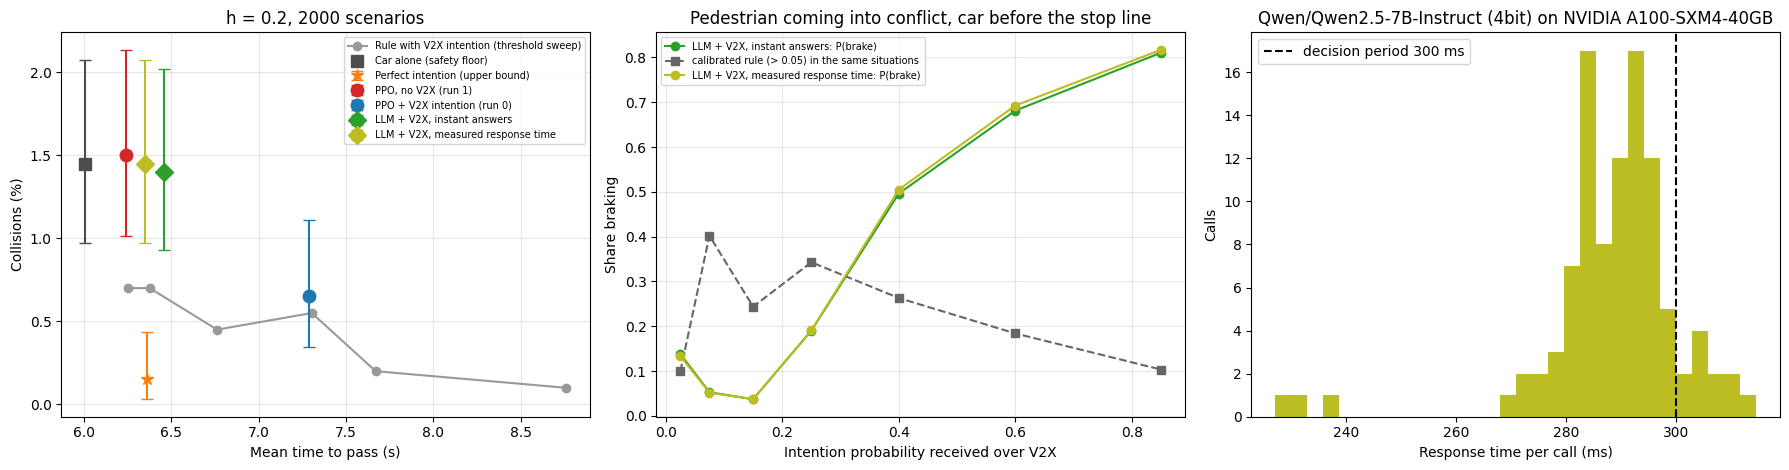

In [16]:
# ===== CELL R: results, paired with version 6 on the same test scenarios
llm = pd.read_csv(f_eps).drop_duplicates(["condition", "ep"])
dec = pd.read_csv(f_dec).drop_duplicates(["condition", "ep", "t"])
conds = [c for c in CONDITIONS if c in set(llm.condition)]
seeds = sorted(set.intersection(*(set(llm[llm.condition == c].ep) for c in conds)))
print(f"{len(seeds)} test scenarios finished in every LLM condition (h = {EVAL_H})\n")


def v6(policy, run=None):
    d = ep6[(ep6.policy == policy) & np.isclose(ep6.h, EVAL_H) & ep6.ep.isin(seeds)]
    if run is not None:
        d = d[d.run == run]
    return d.sort_values("ep").reset_index(drop=True)


def llm_eps(cond):
    """brake_share for the LLM car is the share of time spent braking: with slow answers, decisions are not 0.3 s apart.
    (For version 6 cars, decisions are 0.3 s apart, so their share of decisions is their share of time.)"""
    d = llm[(llm.condition == cond) & llm.ep.isin(seeds)].sort_values("ep").reset_index(drop=True)
    return d.assign(brake_share=d.brake_time_share)


ref_entries = [("Car alone (safety floor)", v6("Car alone (safety floor)")),
               ("Rule: brake for every approaching pedestrian", v6("Rule: brake for every approaching pedestrian")),
               (f"Rule: V2X intention > {tau_star} (calibrated)", v6(cal_label)),
               ("Perfect intention (upper bound)", v6("Perfect intention (upper bound)")),
               (f"PPO, no V2X (run {chosen['PPO, no V2X']})", v6("PPO, no V2X", chosen["PPO, no V2X"])),
               (f"PPO + V2X intention (run {chosen['PPO + V2X intention']})", v6("PPO + V2X intention", chosen["PPO + V2X intention"]))]
entries = ref_entries + [(c, llm_eps(c)) for c in conds]
cols = ["collisions", "collision_pct", "ci_low", "ci_high", "near_miss_pct", "time_to_pass_s", "brake_share_pct"]
tab = pd.DataFrame([dict(policy=k, **summarize(d)) for k, d in entries])
print(tab[["policy"] + cols].round(2).to_string(index=False))
for name in ("PPO, no V2X", "PPO + V2X intention"):
    r = pd.DataFrame([summarize(v6(name, run)) for run in sorted(ep6[ep6.policy == name].run.dropna().unique())])
    print(f"  {name}, all {len(r)} runs on these scenarios: collisions {r.collision_pct.mean():.2f} +/- {r.collision_pct.std():.2f}%, "
          f"time {r.time_to_pass_s.mean():.2f} +/- {r.time_to_pass_s.std():.2f} s")
tab.to_csv(os.path.join(llm_dir, f"summary_llm_h{EVAL_H}.csv"), index=False)


tests = []


def paired(a, b, la, lb):
    assert (a.ep.values == b.ep.values).all()
    n10, n01, p = mcnemar_exact(a.collision.values, b.collision.values)
    tests.append((f"{la} vs {lb}", p))
    both = a.passed.values & b.passed.values
    dt = a.time.values[both] - b.time.values[both]
    bs = [np.random.default_rng(i).choice(dt, len(dt)).mean() for i in range(1000)]
    print(f"  {la} vs {lb}: collisions only in the first {n10}, only in the second {n01}, McNemar p = {p:.4f}; "
          f"time difference {dt.mean():+.2f} s (95% CI {np.percentile(bs, 2.5):+.2f} to {np.percentile(bs, 97.5):+.2f})")


print("\npaired comparisons on the same scenarios")
for c in conds:
    for lb, d in ref_entries:
        if not lb.startswith("Rule: brake for every"):
            paired(llm_eps(c), d, c, lb)
if len(conds) == 2:
    paired(llm_eps(conds[1]), llm_eps(conds[0]), conds[1], conds[0])
order = np.argsort([p for _, p in tests]); m = len(tests); run_max = 0.0
print(f"\nHolm-adjusted McNemar p-values ({m} tests)")
for k, i in enumerate(order):
    run_max = max(run_max, min(1.0, (m - k) * tests[i][1]))
    print(f"  {run_max:.4f}  {tests[i][0]}")

print("\nhow the LLM decides")
for c in conds:
    d = dec[(dec.condition == c) & dec.ep.isin(seeds)]
    print(f"{c}: {len(d)} LLM calls ({len(d) / len(seeds):.1f} per scenario); probability mass on the answer words "
          f"{d.mass.mean():.3f} (below 0.5 in {100 * (d.mass < 0.5).mean():.1f}% of calls); "
          f"same choice as the calibrated rule in {100 * (d.action == d.rule_action).mean():.1f}% of calls")
    print(pd.crosstab(d.rule_action.map(ANSWER_WORDS).rename("rule"), d.action.map(ANSWER_WORDS).rename("LLM")))

# plots: trade-off, braking against the received intention, response time
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
rules = [(lab, v6(lab)) for lab in sorted(ep6.policy.unique()) if lab.startswith("Rule:")]
rr = pd.DataFrame([summarize(d) for _, d in rules]).sort_values("time_to_pass_s")
ax.plot(rr.time_to_pass_s, rr.collision_pct, "-o", color="0.6", label="Rule with V2X intention (threshold sweep)")
mk = ["s", None, None, "*", "o", "o", "D", "D"]
col = ["0.3", None, None, "tab:orange", "tab:red", "tab:blue", "tab:green", "tab:olive"]
for (lab, d), m, cc in zip(entries, mk, col):
    if m is None:
        continue
    s = summarize(d)
    ax.errorbar(s["time_to_pass_s"], s["collision_pct"], yerr=[[s["collision_pct"] - s["ci_low"]], [s["ci_high"] - s["collision_pct"]]],
                fmt=m, color=cc, ms=9, capsize=4, label=lab)
ax.set_xlabel("Mean time to pass (s)"); ax.set_ylabel("Collisions (%)"); ax.set_title(f"h = {EVAL_H}, {len(seeds)} scenarios")
ax.grid(alpha=0.3); ax.legend(fontsize=7)
ax = axes[1]
bins = [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0001]
for c, cc in zip(conds, ("tab:green", "tab:olive")):
    d = dec[(dec.condition == c) & dec.conflict & (dec.gap > STOP_MARGIN) & dec.ep.isin(seeds)].copy()
    d["bin"] = pd.cut(d.p_used, bins, right=False)
    g = d.groupby("bin", observed=True)
    mid = [iv.left + (min(iv.right, 1) - iv.left) / 2 for iv in g.size().index]
    ax.plot(mid, g.p_brake.mean().values, "-o", color=cc, label=f"{c}: P(brake)")
    if c == conds[0]:
        ax.plot(mid, g.rule_action.apply(lambda x: (x == 2).mean()).values, "--s", color="0.4",
                label=f"calibrated rule (> {tau_star}) in the same situations")
ax.set_xlabel("Intention probability received over V2X"); ax.set_ylabel("Share braking")
ax.set_title("Pedestrian coming into conflict, car before the stop line"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
ax = axes[2]
ax.hist(1000 * lat_meas, bins=30, color="tab:olive")
ax.axvline(300, color="k", ls="--", label="decision period 300 ms")
ax.set_xlabel("Response time per call (ms)"); ax.set_ylabel("Calls"); ax.set_title(f"{MODEL_ID} ({QUANT}) on {gpu}"); ax.legend()
plt.tight_layout(); plt.show()


## Optional: how slow can the LLM be?

In [17]:
# ===== CELL X: optional, how slow can the LLM be? (fixed response times)
RUN_SWEEP = True
SWEEP_LATENCY = [0.3, 0.6, 1.0]     # seconds
SWEEP_EPISODES = 500
if RUN_SWEEP:
    sweep = {f"LLM + V2X, {L} s response": float(L) for L in SWEEP_LATENCY}
    fs_eps, _ = run_conditions(sweep, SWEEP_EPISODES, f"sweep_h{EVAL_H}")
    sw = pd.read_csv(fs_eps).drop_duplicates(["condition", "ep"])
    base = llm[llm.condition == conds[0]]
    rows = [dict(condition=conds[0], **summarize(base[base.ep.isin(sw.ep.unique())]))]
    rows += [dict(condition=c, **summarize(g)) for c, g in sw.groupby("condition", sort=False)]
    print(pd.DataFrame(rows)[["condition", "collisions", "collision_pct", "ci_low", "ci_high", "time_to_pass_s"]].round(2).to_string(index=False))


finished: /content/drive/MyDrive/Colab Notebooks/checkpoints_v6/env4480df20_v6e447b6bc_ppo8cd5154a_t0.15/llm_QwenQwen257BInstruct_4bit_06457b/episodes_sweep_h0.2.csv
                 condition  collisions  collision_pct  ci_low  ci_high  time_to_pass_s
LLM + V2X, instant answers          10            2.0    0.96     3.65            6.32
 LLM + V2X, 0.3 s response          10            2.0    0.96     3.65            6.20
 LLM + V2X, 0.6 s response          10            2.0    0.96     3.65            6.11
 LLM + V2X, 1.0 s response          10            2.0    0.96     3.65            6.17


prefix cache self-test: tokens match True, largest probability difference 0.0106, same answers True -> cache on
LLM + V2X, A, cost hint: finished (/content/drive/MyDrive/Colab Notebooks/checkpoints_v6/env4480df20_v6e447b6bc_ppo8cd5154a_t0.15/llm_QwenQwen257BInstruct_4bit_06457b/episodes_ablation_de3259_h0.2.csv)
prefix cache self-test: tokens match True, largest probability difference 0.0077, same answers True -> cache on
LLM + V2X, B, explicit threshold: finished (/content/drive/MyDrive/Colab Notebooks/checkpoints_v6/env4480df20_v6e447b6bc_ppo8cd5154a_t0.15/llm_QwenQwen257BInstruct_4bit_06457b/episodes_ablation_dd34e6_h0.2.csv)

2000 scenarios, h = 0.2, instant answers
                                 policy  collisions  collision_pct  ci_low  ci_high  near_miss_pct  time_to_pass_s  brake_share_pct
               Car alone (safety floor)          29           1.45    0.97     2.08           2.90            6.01             0.00
Rule: V2X intention > 0.05 (calibrated)           4      

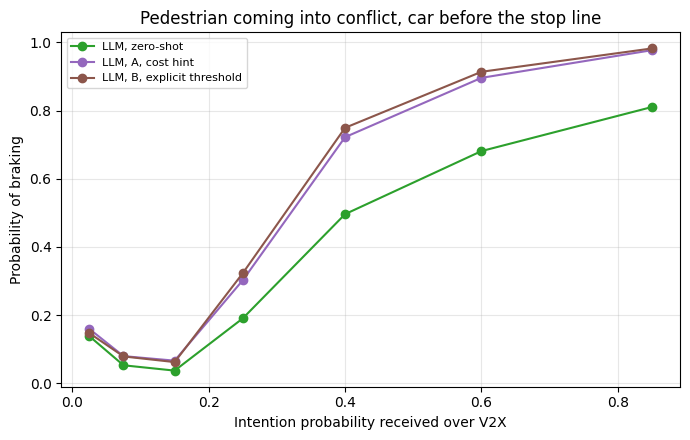

In [18]:
# ===== CELL AB: ablation, two prompt variants (instant answers, the same test scenarios; resumable)
# A adds a qualitative cost hint, B states the decision rule with the calibrated threshold. Everything else is unchanged:
# same model already loaded, same situation text, same scenarios. The zero-shot run above stays the main LLM result.
ABL_EPISODES = 2000
ABLATIONS = {
    "A, cost hint": "Because a collision is so costly, small probabilities matter: brake early even when the probability is low.",
    "B, explicit threshold": (f"Rule: brake when the pedestrian is on the road, or when the probability is above {tau_star} and the pedestrian "
                              "reaches the road no later than 1 s after you reach the crossing. Otherwise, go."),
}


def variant_driver(base, hint):
    """Same model and situation text; instructions with one extra paragraph before the answer line."""
    prompt = SYSTEM_PROMPT.replace("\n\nAnswer with one word", f"\n\n{hint}\n\nAnswer with one word")
    assert prompt != SYSTEM_PROMPT
    d = copy.copy(base); d.cache, d.calls = {}, 0
    kw = dict(tokenize=False, add_generation_prompt=True, enable_thinking=False)
    full = d.tok.apply_chat_template([{"role": "system", "content": prompt}, {"role": "user", "content": "@@STATE@@"}], **kw)
    d.pre_text, d.post_text = full.split("@@STATE@@")
    if base.use_prefix:
        d.pre_ids = d._ids(d.pre_text)
        with torch.no_grad():
            d.pre_kv = d.base(input_ids=torch.tensor([d.pre_ids], device=d.dev), use_cache=True).past_key_values
        d.self_test(probe[:16], tol=0.05)
    return d, hashlib.md5(prompt.encode()).hexdigest()[:6]


abl_files = {}
for name, hint in ABLATIONS.items():
    d, key = variant_driver(driver, hint)
    cond = f"LLM + V2X, {name}"
    f_a, f_ad = (os.path.join(llm_dir, f"{k}_ablation_{key}_h{EVAL_H}.csv") for k in ("episodes", "decisions"))
    abl_files[cond] = (f_a, f_ad)
    done = set(pd.read_csv(f_a).ep) if os.path.exists(f_a) else set()
    t0, n_new = time.time(), 0
    for start in range(0, ABL_EPISODES, CHUNK):
        todo = [s for s in range(10_000 + start, 10_000 + min(start + CHUNK, ABL_EPISODES)) if s not in done]
        if not todo:
            continue
        log = []
        df = run_driver(d, EVAL_H, todo, latency=None, log=log, tau_ref=tau_star)
        lg = pd.DataFrame(log); lg.insert(0, "condition", cond); df.insert(0, "condition", cond)
        lg.to_csv(f_ad, mode="a", header=not os.path.exists(f_ad), index=False)
        df.to_csv(f_a, mode="a", header=not os.path.exists(f_a), index=False)
        done |= set(todo); n_new += len(todo)
        rate = (time.time() - t0) / n_new
        res = pd.read_csv(f_a)
        print(f"{cond}: {len(done)}/{ABL_EPISODES} episodes, {int(res.collision.sum())} collisions so far, "
              f"about {(ABL_EPISODES - len(done)) * rate / 60:.0f} min left", flush=True)
    print(f"{cond}: finished ({f_a})")

# results on the scenarios finished in every variant
abl = {c: pd.read_csv(fa).drop_duplicates("ep") for c, (fa, _) in abl_files.items()}
s_ab = sorted(set(seeds).intersection(*(set(v.ep) for v in abl.values())))
pick_ep = lambda d: d[d.ep.isin(s_ab)].sort_values("ep").reset_index(drop=True)
zs = pick_ep(llm_eps(conds[0]))
ab_entries = [("Car alone (safety floor)", pick_ep(v6("Car alone (safety floor)"))),
              (f"Rule: V2X intention > {tau_star} (calibrated)", pick_ep(v6(cal_label))),
              (f"PPO + V2X intention (run {chosen['PPO + V2X intention']})", pick_ep(v6("PPO + V2X intention", chosen["PPO + V2X intention"]))),
              ("LLM + V2X, zero-shot (main result)", zs)]
ab_entries += [(c, pick_ep(v.assign(brake_share=v.brake_time_share))) for c, v in abl.items()]
print(f"\n{len(s_ab)} scenarios, h = {EVAL_H}, instant answers")
print(pd.DataFrame([dict(policy=k, **summarize(v)) for k, v in ab_entries])[["policy"] + cols].round(2).to_string(index=False))
print("\npaired comparisons")
for c in abl:
    for lb, ref in ab_entries[:4]:
        paired(pick_ep(abl[c].assign(brake_share=abl[c].brake_time_share)), ref, c, lb)

fig, ax = plt.subplots(figsize=(7, 4.5))
for c, cc in [(conds[0], "tab:green")] + list(zip(abl, ("tab:purple", "tab:brown"))):
    dd = dec[dec.condition == c] if c == conds[0] else pd.read_csv(abl_files[c][1]).drop_duplicates(["ep", "t"])
    dd = dd[dd.conflict & (dd.gap > STOP_MARGIN) & dd.ep.isin(s_ab)].copy()
    dd["bin"] = pd.cut(dd.p_used, bins, right=False)
    gg = dd.groupby("bin", observed=True)
    mid = [iv.left + (min(iv.right, 1) - iv.left) / 2 for iv in gg.size().index]
    ax.plot(mid, gg.p_brake.mean().values, "-o", color=cc, label=("LLM, zero-shot" if c == conds[0] else c.replace("LLM + V2X, ", "LLM, ")))
ax.set_xlabel("Intention probability received over V2X"); ax.set_ylabel("Probability of braking")
ax.set_title("Pedestrian coming into conflict, car before the stop line"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [19]:
# ===== CELL C: ablation C, few-shot examples (instant answers, the same test scenarios; resumable). Run Cell AB first.
# Eight worked examples are added to the instructions. Situations come from scenarios outside the test range
# (seeds 700,000+) while the calibrated rule drives; the answer shown is the rule's choice. No rule text is given.
C_EPISODES = 2000
N_EXAMPLE_EPISODES = 300


class TraceDriver:
    """Wraps a driver and records, for every question: the situation text, its answer, the calibrated rule's choice
    and the car's own estimate (sidewalk or road, distance, intention, visibility, metres left before braking must start)."""
    def __init__(self, inner, tau):
        self.inner, self.rule, self.rows = inner, RiskRule(tau), []

    def decide(self, states, envs):
        out = self.inner.decide(states, envs)
        for s, e, o in zip(states, envs, out):
            c = e.cfg; x, vx = e.est
            stop = e.sv ** 2 / (2 * c.a_brake) + e.sv * c.dt * c.action_repeat
            self.rows.append(dict(state=s, t=round(e.t * c.dt, 1),
                                  action=o[0], p_brake=o[1][2] if o[1] else np.nan, rule=self.rule(e, None),
                                  sidewalk=bool(x > c.xc + c.road_half), on_road=bool(abs(x - c.xc) <= c.road_half),
                                  in_path=bool(abs(x - e.xv) <= c.car_w / 2 + c.ped_r), conflict=bool(_conflict_est(e)),
                                  p=float(e.p_used), visible=bool(e._visible()), gap=e._front_gap(), speed=e.sv,
                                  margin=e._front_gap() - STOP_MARGIN - stop))
        return out


def pick_examples(tr):
    """Eight situations of distinct kinds, first match in scenario order; the label is the calibrated rule's choice."""
    kinds = [("hidden pedestrian near the road, moderate intention, braking must start", lambda r: r.sidewalk and r.rule == 2 and not r.visible and 0.05 < r.p < 0.5 and r.speed > 4),
             ("pedestrian near the road, higher intention, braking must start", lambda r: r.sidewalk and r.rule == 2 and r.p >= 0.3 and r.speed > 4),
             ("low intention, close to the crossing", lambda r: r.sidewalk and r.conflict and r.rule == 0 and r.p <= tau_star and r.margin <= 2),
             ("intention above the threshold but still far", lambda r: r.sidewalk and r.conflict and r.rule == 0 and r.p > tau_star and r.margin > 5),
             ("pedestrian on the road in the car's path", lambda r: r.on_road and r.in_path and r.rule == 2),
             ("pedestrian on the road, not yet in the path", lambda r: r.on_road and not r.in_path and r.rule == 2),
             ("no conflict", lambda r: r.sidewalk and not r.conflict and r.rule == 0),
             ("past the stop line, pedestrian on the sidewalk", lambda r: r.gap <= STOP_MARGIN and r.sidewalk and r.rule == 0)]
    ex = []
    for name, f in kinds:
        m = tr[tr.apply(f, axis=1)]
        if len(m):
            r = m.iloc[len(m) // 2]
            ex.append((name, r.state.rsplit("\n", 1)[0], ANSWER_WORDS[int(r.rule)]))
    return ex


rec_c = TraceDriver(RuleDriver(tau_star), tau_star)
run_driver(rec_c, EVAL_H, range(700_000, 700_000 + N_EXAMPLE_EPISODES))
examples = pick_examples(pd.DataFrame(rec_c.rows))
hint_c = "Examples of good decisions:\n\n" + "\n\n".join(f"Situation:\n{s}\nAnswer: {a}" for _, s, a in examples)
print(f"{len(examples)} examples:", [(n, a) for n, _, a in examples])
print("\n" + hint_c[:1500] + ("..." if len(hint_c) > 1500 else ""))


def run_prompt_variant(cond, hint, n_episodes):
    d, key = variant_driver(driver, hint)
    f_a, f_ad = (os.path.join(llm_dir, f"{k}_ablation_{key}_h{EVAL_H}.csv") for k in ("episodes", "decisions"))
    done = set(pd.read_csv(f_a).ep) if os.path.exists(f_a) else set()
    t0, n_new = time.time(), 0
    for start in range(0, n_episodes, CHUNK):
        todo = [s for s in range(10_000 + start, 10_000 + min(start + CHUNK, n_episodes)) if s not in done]
        if not todo:
            continue
        log = []
        df = run_driver(d, EVAL_H, todo, latency=None, log=log, tau_ref=tau_star)
        lg = pd.DataFrame(log); lg.insert(0, "condition", cond); df.insert(0, "condition", cond)
        lg.to_csv(f_ad, mode="a", header=not os.path.exists(f_ad), index=False)
        df.to_csv(f_a, mode="a", header=not os.path.exists(f_a), index=False)
        done |= set(todo); n_new += len(todo)
        rate = (time.time() - t0) / n_new
        print(f"{cond}: {len(done)}/{n_episodes} episodes, {int(pd.read_csv(f_a).collision.sum())} collisions so far, "
              f"about {(n_episodes - len(done)) * rate / 60:.0f} min left", flush=True)
    return f_a, f_ad


cond_c = "LLM + V2X, C, few-shot examples"
abl_files[cond_c] = run_prompt_variant(cond_c, hint_c, C_EPISODES)


def signflip_vs_ppo(L, n=200_000):
    """Paired test against the per-scenario mean of all PPO + V2X runs (one test, not one per run)."""
    pp = ep6[np.isclose(ep6.h, EVAL_H) & (ep6.policy == "PPO + V2X intention")]
    m = pp.pivot(index="ep", columns="run", values="collision").astype(float).mean(axis=1)
    d = (L.set_index("ep").collision.astype(float) - m.loc[L.ep].values).values
    d = d[d != 0]
    sims = (np.random.default_rng(0).choice([-1, 1], size=(n, len(d))) * d).sum(1)
    return m.loc[L.ep].sum(), float((np.abs(sims) >= abs(d.sum()) - 1e-9).mean())


# results on the scenarios finished in every LLM variant
var = {conds[0]: llm[llm.condition == conds[0]]}
var.update({c: pd.read_csv(fa).drop_duplicates("ep") for c, (fa, _) in abl_files.items()})
s_all = sorted(set(seeds).intersection(*(set(v.ep) for v in var.values())))
pick_ep = lambda d: d[d.ep.isin(s_all)].sort_values("ep").reset_index(drop=True)
rows = [dict(policy=k, **summarize(pick_ep(v6(lab) if run is None else v6(lab, run))))
        for k, lab, run in (("Car alone (safety floor)", "Car alone (safety floor)", None),
                            (f"Rule: V2X intention > {tau_star} (calibrated)", cal_label, None),
                            ("Perfect intention (upper bound)", "Perfect intention (upper bound)", None))]
for name in ("PPO, no V2X", "PPO + V2X intention"):
    r = pd.DataFrame([summarize(pick_ep(v6(name, run))) for run in sorted(ep6[ep6.policy == name].run.dropna().unique())])
    rows.append(dict(policy=f"{name} (mean of {len(r)} runs)", **r.mean(numeric_only=True).to_dict()))
for c, v in var.items():
    rows.append(dict(policy=c, **summarize(pick_ep(v.assign(brake_share=v.brake_time_share)))))
print(f"\n{len(s_all)} scenarios finished in every LLM variant (h = {EVAL_H}, instant answers)")
print(pd.DataFrame(rows)[["policy"] + cols].round(2).to_string(index=False))

print("\npaired tests")
for c, v in var.items():
    L = pick_ep(v)
    mean_ppo, p_ppo = signflip_vs_ppo(L)
    n10, n01, p_rule = mcnemar_exact(L.collision.values, pick_ep(v6(cal_label)).collision.values)
    print(f"  {c}: {int(L.collision.sum())} collisions; vs PPO + V2X (mean {mean_ppo:.1f}) p = {p_ppo:.4f}; "
          f"vs calibrated rule {n10} / {n01}, p = {p_rule:.4f}")
    if c != conds[0]:
        n10, n01, p = mcnemar_exact(L.collision.values, pick_ep(var[conds[0]]).collision.values)
        print(f"      vs zero-shot: {n10} / {n01}, p = {p:.4f}")

print("\nbraking while the pedestrian is still on the sidewalk (conflict coming, car before the stop line)")
tab = {}
for c in var:
    dd = (dec[dec.condition == c] if c == conds[0] else pd.read_csv(abl_files[c][1])).drop_duplicates(["ep", "t"])
    dd = dd[dd.ep.isin(s_all) & dd.conflict & (dd.gap > STOP_MARGIN) & (dd.ped_from_road > 0)].copy()
    dd["bin"] = pd.cut(dd.p_used, bins, right=False)
    g = dd.groupby("bin", observed=True)
    tab[c.replace("LLM + V2X, ", "")] = g.p_brake.mean()
    if c == conds[0]:
        tab["calibrated rule"] = g.rule_action.apply(lambda x: (x == 2).mean())
print(pd.DataFrame(tab).round(3).to_string())

8 examples: [('hidden pedestrian near the road, moderate intention, braking must start', 'brake'), ('pedestrian near the road, higher intention, braking must start', 'brake'), ('low intention, close to the crossing', 'go'), ('intention above the threshold but still far', 'go'), ("pedestrian on the road in the car's path", 'brake'), ('pedestrian on the road, not yet in the path', 'brake'), ('no conflict', 'go'), ('past the stop line, pedestrian on the sidewalk', 'go')]

Examples of good decisions:

Situation:
Your car: speed 6.7 m/s, 12.3 m before the crossing (1.8 s at this speed). Stop line in 10.9 m. You need 9.9 m to stop.
Pedestrian (roadside unit, message 0.1 s old; hidden from your own sensors): on the sidewalk, 2.5 m from the road, walking toward the road at 1.5 m/s (reaches it in 1.6 s).
1 s ago: on the sidewalk, 4.4 m from the road, walking toward the road at 1.3 m/s.
Roadside unit estimate of the probability that the pedestrian walks onto the road without stopping: 0.17.
Your

In [20]:
# ===== CELL D: reasoning check (step-by-step answers on selected situations; not a driving run). Run Cell C first.
# Does thinking before answering make the LLM brake for a pedestrian who is still on the sidewalk? Situations:
# the moment the calibrated rule first wanted to brake in each zero-shot collision, plus sidewalk situations
# from test scenarios 10,000-10,299 where the rule brakes or not. The zero-shot LLM drives, as in Cell T.
D_SIDEWALK = 150             # situations of each kind (rule brakes / rule goes)
D_MAX_NEW = 220              # tokens the model may write
D_BATCH = 16
REASON_LINE = ("Think step by step in at most 120 words: where the pedestrian will be when you reach the crossing, "
               "and whether you can still stop. Then write your final answer on the last line as "
               "'Answer: go', 'Answer: keep' or 'Answer: brake'.")
prompt_d = SYSTEM_PROMPT.replace("Answer with one word: go, keep or brake.", REASON_LINE)
assert prompt_d != SYSTEM_PROMPT

zs_ep = llm[llm.condition == conds[0]]
coll_seeds = sorted(zs_ep[zs_ep.collision].ep)
tr_d = TraceDriver(driver, tau_star)
run_driver(tr_d, EVAL_H, sorted(set(coll_seeds) | set(range(10_000, 10_300))))
T = pd.DataFrame(tr_d.rows)
side = T[T.sidewalk & T.conflict & (T.gap > STOP_MARGIN)]
print(f"{len(T)} questions recorded, {len(side)} with the pedestrian on the sidewalk coming into conflict")


def collision_moments():
    """Re-run each collision scenario alone and keep the first situation where the rule wants to brake."""
    out = []
    for s in coll_seeds:
        tr = TraceDriver(driver, tau_star); run_driver(tr, EVAL_H, [s])
        r = [row for row in tr.rows if row["rule"] == 2]
        if r:
            out.append(dict(r[0], ep=s))
    return pd.DataFrame(out)


crit = collision_moments()
rng = np.random.default_rng(0)
sw = side.drop_duplicates("state")
sw_b, sw_g = sw[sw.rule == 2], sw[sw.rule == 0]
sel = pd.concat([crit.assign(group="collision moment"),
                 sw_b.iloc[rng.permutation(len(sw_b))[:D_SIDEWALK]].assign(group="sidewalk, rule brakes"),
                 sw_g.iloc[rng.permutation(len(sw_g))[:D_SIDEWALK]].assign(group="sidewalk, rule goes")], ignore_index=True)
print("situations:", sel.group.value_counts().to_dict())


def reason(states):
    tok, m = driver.tok, driver.model
    kw = dict(tokenize=False, add_generation_prompt=True, enable_thinking=False)
    texts = [tok.apply_chat_template([{"role": "system", "content": prompt_d}, {"role": "user", "content": s}], **kw) for s in states]
    old = tok.padding_side; tok.padding_side = "left"
    enc = tok(texts, return_tensors="pt", padding=True, add_special_tokens=False).to(driver.dev)
    tok.padding_side = old
    with torch.no_grad():
        out = m.generate(**enc, max_new_tokens=D_MAX_NEW, do_sample=False, pad_token_id=driver.pad)
    return tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)


def parse(txt):
    import re
    m = re.findall(r"answer\s*:\s*\**\s*(go|keep|brake)", txt.lower())
    return {"go": 0, "keep": 1, "brake": 2}[m[-1]] if m else -1


f_d = os.path.join(llm_dir, f"reasoning_h{EVAL_H}.csv")
if os.path.exists(f_d):
    res_d = pd.read_csv(f_d)
    print("loaded", f_d)
else:
    t0, outs = time.time(), []
    for i in range(0, len(sel), D_BATCH):
        outs += reason(list(sel.state.iloc[i:i + D_BATCH]))
        print(f"  {min(i + D_BATCH, len(sel))}/{len(sel)} situations, {time.time() - t0:.0f} s", flush=True)
    res_d = sel.assign(reasoning=outs, cot_action=[parse(o) for o in outs]).drop(columns=["state"])
    res_d.to_csv(f_d, index=False)

sync = torch.cuda.synchronize if driver.dev.type == "cuda" else (lambda: None)
lat_d = []
for s in sel.state.iloc[:3]:
    t0 = time.time(); reason([s]); sync(); lat_d.append(time.time() - t0)
print(f"\nresponse time with reasoning (single call): {np.mean(lat_d):.1f} s on average, against "
      f"{1000 * np.median(lat_meas):.0f} ms for a one-word answer")
print(f"answers that could not be read: {int((res_d.cot_action == -1).sum())} of {len(res_d)}")
summ_d = res_d.groupby("group").agg(n=("cot_action", "size"),
                                    one_word_brakes=("action", lambda x: (x == 2).mean()),
                                    with_reasoning_brakes=("cot_action", lambda x: (x == 2).mean()),
                                    with_reasoning_unreadable=("cot_action", lambda x: (x == -1).mean()))
print(summ_d.round(3).to_string())
for g in ("collision moment", "sidewalk, rule goes"):
    r = res_d[res_d.group == g]
    if len(r):
        print(f"\nexample ({g}): one-word answer {ANSWER_WORDS.get(int(r.action.iloc[0]), '?')}; with reasoning:\n{r.reasoning.iloc[0][:900]}")

5570 questions recorded, 2173 with the pedestrian on the sidewalk coming into conflict
situations: {'sidewalk, rule brakes': 150, 'sidewalk, rule goes': 150, 'collision moment': 28}
loaded /content/drive/MyDrive/Colab Notebooks/checkpoints_v6/env4480df20_v6e447b6bc_ppo8cd5154a_t0.15/llm_QwenQwen257BInstruct_4bit_06457b/reasoning_h0.2.csv

response time with reasoning (single call): 4.0 s on average, against 291 ms for a one-word answer
answers that could not be read: 1 of 328
                         n  one_word_brakes  with_reasoning_brakes  with_reasoning_unreadable
group                                                                                        
collision moment        28            0.036                  0.750                      0.000
sidewalk, rule brakes  150            0.000                  0.767                      0.007
sidewalk, rule goes    150            0.000                  0.567                      0.000

example (collision moment): one-word answer keep

## Variant C′, a second set of eight examples
Cell C2 below. Supplementary S1.4.

In [21]:
# ===== CELL C2: second example set (same design as Cell C; examples from seeds 800,000+). Run after Cell C.
rec_c2 = TraceDriver(RuleDriver(tau_star), tau_star)
run_driver(rec_c2, EVAL_H, range(800_000, 800_000 + N_EXAMPLE_EPISODES))
examples2 = pick_examples(pd.DataFrame(rec_c2.rows))
hint_c2 = "Examples of good decisions:\n\n" + "\n\n".join(f"Situation:\n{s}\nAnswer: {a}" for _, s, a in examples2)
print(f"{len(examples2)} examples:", [(n, a) for n, _, a in examples2])
print("examples identical to set 1:", sum(s1 == s2 for (_, s1, _), (_, s2, _) in zip(examples, examples2)))
assert hint_c2 != hint_c
cond_c2 = "LLM + V2X, C, second example set"
abl_files[cond_c2] = run_prompt_variant(cond_c2, hint_c2, C_EPISODES)

# results on the same scenarios, with paired tests
L1 = pd.read_csv(abl_files[cond_c][0]).drop_duplicates("ep")
L2 = pd.read_csv(abl_files[cond_c2][0]).drop_duplicates("ep")
Z = llm[llm.condition == conds[0]].drop_duplicates("ep")
common = sorted(set(L1.ep) & set(L2.ep) & set(Z.ep))
sel = lambda d: d[d.ep.isin(common)].sort_values("ep").reset_index(drop=True)
L1, L2, Z, R = sel(L1), sel(L2), sel(Z), sel(v6(cal_label))
for name, L in (("set 1", L1), ("set 2", L2)):
    s = summarize(L.assign(brake_share=L.brake_time_share))
    print(f"{name}: {s['collisions']} collisions ({s['collision_pct']:.2f}%, CI {s['ci_low']:.2f}-{s['ci_high']:.2f}), "
          f"time to pass {s['time_to_pass_s']:.2f} s, braking {s['brake_share_pct']:.1f}% of the time")
for name, other in (("set 1", L1), ("zero-shot", Z), ("calibrated rule", R)):
    n10, n01, p = mcnemar_exact(L2.collision.values, other.collision.values)
    print(f"set 2 vs {name}: {n10} / {n01}, p = {p:.4f}")
m, p = signflip_vs_ppo(L2)
print(f"set 2 vs PPO + V2X (mean {m:.1f} collisions): p = {p:.4f}")

8 examples: [('hidden pedestrian near the road, moderate intention, braking must start', 'brake'), ('pedestrian near the road, higher intention, braking must start', 'brake'), ('low intention, close to the crossing', 'go'), ('intention above the threshold but still far', 'go'), ("pedestrian on the road in the car's path", 'brake'), ('pedestrian on the road, not yet in the path', 'brake'), ('no conflict', 'go'), ('past the stop line, pedestrian on the sidewalk', 'go')]
examples identical to set 1: 0
prefix cache self-test: tokens match True, largest probability difference 0.0111, same answers True -> cache on
set 1: 10 collisions (0.50%, CI 0.24-0.92), time to pass 8.14 s, braking 30.4% of the time
set 2: 20 collisions (1.00%, CI 0.61-1.54), time to pass 8.51 s, braking 35.2% of the time
set 2 vs set 1: 16 / 6, p = 0.0525
set 2 vs zero-shot: 20 / 28, p = 0.3123
set 2 vs calibrated rule: 20 / 4, p = 0.0015
set 2 vs PPO + V2X (mean 10.6 collisions): p = 0.0261


## LLM agent under hesitation and channel faults

In [22]:
# ===== CELL H: the LLM agent under pedestrian hesitation and V2X channel faults (instant answers; resumable). Run Cell C first.
# The agent is variant C of the paper: the same model and the same eight examples as Cell C, unchanged. It is tested
# under the conditions used for the RL agent: hesitation h = 0, 0.4, 0.6 and 0.8 without faults, and five channel
# faults at h = 0.2. Same 2,000 test scenarios (seeds 10,000+) in every condition. The calibrated rule is re-run under
# every condition on the same scenarios (CPU, a minute or two each), so each comparison is paired.
# Results go to new files in llm_dir; nothing earlier is changed. Run the cell again to continue after a disconnection.
from dataclasses import replace

H_EPISODES = 2000
SWEEP = [   # (label, h, V2X settings). Order of priority: if GPU time runs out, the first ones matter most.
    ("RSU down", 0.2, dict(v2x_loss=1.0)),
    ("30% loss", 0.2, dict(v2x_loss=0.30)),
    ("+500 ms delay", 0.2, dict(extra_delay=5)),
    ("h = 0.8", 0.8, {}),
    ("h = 0.0", 0.0, {}),
    ("10% loss", 0.2, dict(v2x_loss=0.10)),
    ("+300 ms delay", 0.2, dict(extra_delay=3)),
    ("h = 0.4", 0.4, {}),
    ("h = 0.6", 0.6, {}),
]
SWEEP = SWEEP[:7]
ALSO_ZERO_SHOT = False      # True also runs the zero-shot prompt in every condition (twice the GPU time)

assert "hint_c" in globals(), "run Cell C first (it builds the eight examples of variant C)"
d_c, key_c = variant_driver(driver, hint_c)
f_c02 = os.path.join(llm_dir, f"episodes_ablation_{key_c}_h0.2.csv")
assert os.path.exists(f_c02), f"variant C at h = 0.2 not found ({f_c02}); the examples differ from the paper's run"
print(f"variant C, prompt key {key_c} (the paper's run: {os.path.basename(f_c02)})")
agents = [("LLM, C, eight examples", d_c, key_c)] + ([("LLM, zero-shot", driver, "zeroshot")] if ALSO_ZERO_SHOT else [])
SEEDS_H = list(range(10_000, 10_000 + H_EPISODES))


def run_sweep(name, drv, key):
    f_e, f_d = (os.path.join(llm_dir, f"{k}_sweep_{key}.csv") for k in ("episodes", "decisions"))
    done = set(map(tuple, pd.read_csv(f_e)[["condition", "ep"]].values.tolist())) if os.path.exists(f_e) else set()
    total, t0, n_new = H_EPISODES * len(SWEEP), time.time(), 0
    for lab, h, kw in SWEEP:
        vc = replace(vcfg, **kw)
        for start in range(0, H_EPISODES, CHUNK):
            todo = [s for s in SEEDS_H[start:start + CHUNK] if (lab, s) not in done]
            if not todo:
                continue
            log = []
            df = run_driver(drv, h, todo, latency=None, vcfg=vc, log=log, tau_ref=tau_star)
            lg = pd.DataFrame(log)
            for x in (df, lg):
                x.insert(0, "h", h); x.insert(0, "condition", lab)
            if len(lg):
                lg.to_csv(f_d, mode="a", header=not os.path.exists(f_d), index=False)
            df.to_csv(f_e, mode="a", header=not os.path.exists(f_e), index=False)
            done |= {(lab, s) for s in todo}; n_new += len(todo)
            rate = (time.time() - t0) / n_new
            res = pd.read_csv(f_e); r = res[res.condition == lab]
            print(f"{name}, {lab}: {len(r)}/{H_EPISODES} scenarios, {int(r.collision.sum())} collisions so far | "
                  f"whole sweep {len(done)}/{total}, about {(total - len(done)) * rate / 60:.0f} min left", flush=True)
    print(f"{name}: finished ({f_e})")
    return f_e


f_sweep = {name: run_sweep(name, drv, key) for name, drv, key in agents}

# the calibrated rule under every condition, on the same scenarios (no GPU)
f_rule = os.path.join(llm_dir, "episodes_sweep_rule.csv")
rule_done = set(pd.read_csv(f_rule).condition) if os.path.exists(f_rule) else set()
for lab, h, kw in SWEEP:
    if lab not in rule_done:
        df = run_driver(RuleDriver(tau_star), h, SEEDS_H, vcfg=replace(vcfg, **kw))
        df.insert(0, "h", h); df.insert(0, "condition", lab)
        df.to_csv(f_rule, mode="a", header=not os.path.exists(f_rule), index=False)
rule_sw = pd.read_csv(f_rule).drop_duplicates(["condition", "ep"])
for lab, h, kw in SWEEP:            # check: without faults, the re-run rule must match version 6 on the same scenarios
    old = ep6[(ep6.policy == cal_label) & np.isclose(ep6.h, h) & ep6.ep.isin(SEEDS_H)].sort_values("ep")
    if not kw and len(old):
        new = rule_sw[(rule_sw.condition == lab) & rule_sw.ep.isin(old.ep)].sort_values("ep")
        same = len(new) == len(old) and (new.collision.values == old.collision.values).all() and np.allclose(new.time.values, old.time.values)
        print(f"rule at h = {h}: same outcomes as version 6 on {len(old)} scenarios: {same}")
        assert same, "the re-run rule differs from version 6; stop and check the setup"


def rl_runs(h):
    """PPO + V2X intention, all runs at hesitation h without faults (version 6 test scenarios)."""
    return ep6[np.isclose(ep6.h, h) & (ep6.policy == "PPO + V2X intention") & ep6.ep.isin(SEEDS_H)]


def signflip(L, pp, n=200_000):
    """Paired test of L against the per-scenario mean of all RL runs (as in Cell C)."""
    m = pp.pivot(index="ep", columns="run", values="collision").astype(float).mean(axis=1)
    d = (L.set_index("ep").collision.astype(float) - m.loc[L.ep].values).values
    d = d[d != 0]
    if not len(d):
        return m.loc[L.ep].sum(), 1.0
    sims = (np.random.default_rng(0).choice([-1, 1], size=(n, len(d))) * d).sum(1)
    return m.loc[L.ep].sum(), float((np.abs(sims) >= abs(d.sum()) - 1e-9).mean())


nominal = pd.read_csv(f_c02).drop_duplicates("ep")
rows = []
for name, _, key in agents:
    sw = pd.read_csv(f_sweep[name]).drop_duplicates(["condition", "ep"])
    base = nominal if key == key_c else llm[llm.condition == conds[0]]
    print(f"\n=== {name} ===")
    for lab, h, kw in [("nominal (h = 0.2, 1% loss)", 0.2, {})] + SWEEP:
        L = base if lab.startswith("nominal") else sw[sw.condition == lab]
        if L.empty:
            print(f"{lab}: not run yet"); continue
        L = L[L.ep.isin(SEEDS_H)].sort_values("ep").reset_index(drop=True)
        s = summarize(L.assign(brake_share=L.brake_time_share))
        R = (rule_sw[rule_sw.condition == lab] if not lab.startswith("nominal") else
             ep6[(ep6.policy == cal_label) & np.isclose(ep6.h, 0.2)])
        R = R[R.ep.isin(L.ep)].sort_values("ep").reset_index(drop=True)
        n10, n01, p_rule = mcnemar_exact(L.collision.values, R.collision.values)
        line = (f"{lab}: {s['collisions']} collisions in {s['episodes']} ({s['collision_pct']:.2f}% "
                f"[{s['ci_low']:.2f}, {s['ci_high']:.2f}]), time {s['time_to_pass_s']:.2f} s, braking {s['brake_share_pct']:.1f}% | "
                f"rule {int(R.collision.sum())}, LLM vs rule {n10} / {n01}, p = {p_rule:.4f}")
        row = dict(agent=name, condition=lab, h=h, **s, rule_collisions=int(R.collision.sum()),
                   rule_time_s=float(R[R.passed].time.mean()), mcnemar_vs_rule=p_rule)
        if not lab.startswith("nominal"):
            B = base[base.ep.isin(L.ep)].sort_values("ep").reset_index(drop=True)
            a10, a01, p_nom = mcnemar_exact(L.collision.values, B.collision.values)
            line += f" | vs own nominal {a10} / {a01}, p = {p_nom:.4f}"
            row["mcnemar_vs_nominal"] = p_nom
        if not kw:                                              # no channel fault: the five RL runs exist at this h
            pp = rl_runs(h)
            if len(pp):
                mean_rl, p_rl = signflip(L[L.ep.isin(pp.ep)], pp[pp.ep.isin(L.ep)])
                line += f" | RL + V2X mean of {pp.run.nunique()} runs {mean_rl:.1f}, sign-flip p = {p_rl:.4f}"
                row.update(rl_mean_collisions=mean_rl, signflip_vs_rl=p_rl)
        else:
            rr = rob6[(rob6.policy == "PPO + V2X intention") & (rob6.condition == lab)]
            if len(rr):
                line += f" | RL + V2X (selected run) {rr.collision_pct.iloc[0]:.2f}% (Cell D of version 6)"
        print(line)
        rows.append(row)
summary_sweep = pd.DataFrame(rows)
summary_sweep.to_csv(os.path.join(llm_dir, f"summary_sweep_{key_c}.csv"), index=False)
print("\nsaved:", os.path.join(llm_dir, f"summary_sweep_{key_c}.csv"))
print("files to send:", [os.path.basename(f) for f in f_sweep.values()] + [os.path.basename(f_rule), f"summary_sweep_{key_c}.csv"])

prefix cache self-test: tokens match True, largest probability difference 0.0107, same answers True -> cache on
variant C, prompt key 540ad8 (the paper's run: episodes_ablation_540ad8_h0.2.csv)
LLM, C, eight examples, 10% loss: 100/2000 scenarios, 1 collisions so far | whole sweep 10100/14000, about 23 min left
LLM, C, eight examples, 10% loss: 200/2000 scenarios, 3 collisions so far | whole sweep 10200/14000, about 23 min left
LLM, C, eight examples, 10% loss: 300/2000 scenarios, 4 collisions so far | whole sweep 10300/14000, about 22 min left
LLM, C, eight examples, 10% loss: 400/2000 scenarios, 4 collisions so far | whole sweep 10400/14000, about 22 min left
LLM, C, eight examples, 10% loss: 500/2000 scenarios, 5 collisions so far | whole sweep 10500/14000, about 21 min left
LLM, C, eight examples, 10% loss: 600/2000 scenarios, 5 collisions so far | whole sweep 10600/14000, about 21 min left
LLM, C, eight examples, 10% loss: 700/2000 scenarios, 5 collisions so far | whole sweep 1070

## Variant C+, four added examples
Called C2 in the code of Cell K. Tested on the second scenario set (seeds 40,000+). Supplementary S1.6.

In [25]:
# ===== CELL K: variant C2, examples aimed at the failures found. Run Cells P, S7, M, T, R, AB and C first (as for Cell H).
# C2 keeps the eight examples of variant C and adds four more, aimed at what went wrong: no roadside message (RSU
# failure), an old message, and braking while already on the crossing. The new situations come from scenarios outside
# every range used so far (seeds 900,000+), driven by the calibrated rule; the answer shown is the rule's choice.
# C2 was designed after looking at the test results, so it is tested on 2,000 FRESH scenarios (seeds 40,000+), with
# variant C and the rule on the same scenarios. Resumable: run the cell again after a disconnection.
from dataclasses import replace

K_EPISODES = 2000
K_SEEDS = list(range(40_000, 40_000 + K_EPISODES))
K_CONDS = [("nominal", {}), ("RSU down", dict(v2x_loss=1.0))]
assert "hint_c" in globals() and "TraceDriver" in globals(), "run Cell C first"


def k_trace(vkw, seed0, n):
    """Situations met while the calibrated rule drives, with the rule's choice."""
    tr = TraceDriver(RuleDriver(tau_star), tau_star)
    run_driver(tr, EVAL_H, range(seed0, seed0 + n), vcfg=replace(vcfg, **vkw))
    d = pd.DataFrame(tr.rows)
    d["fresh"] = d.state.str.contains("roadside unit, message")
    d["age"] = d.state.str.extract(r"message ([0-9.]+) s old")[0].astype(float)
    return d


tr_down = k_trace(dict(v2x_loss=1.0), 900_000, 300)
tr_late = k_trace(dict(extra_delay=5), 901_000, 300)
tr_nom = k_trace({}, 902_000, 1000)
extra_kinds = [
    ("no roadside message, pedestrian seen near the road, the car can still pass first", tr_down,
     lambda r: (not r.fresh) and r.sidewalk and r.visible and r.conflict and r.rule == 0),
    ("no roadside message, own estimate above the threshold, braking must start", tr_down,
     lambda r: (not r.fresh) and r.sidewalk and r.rule == 2),
    ("old roadside message, hidden pedestrian, braking must start", tr_late,
     lambda r: r.fresh and r.age >= 0.45 and r.sidewalk and (not r.visible) and r.rule == 2),
    ("on the crossing, pedestrian on the road beside your path: clear the crossing", tr_nom,
     lambda r: r.gap <= 0 and r.on_road and (not r.in_path) and r.rule == 0),
]
extra = []
for name, tr, f in extra_kinds:
    m = tr[tr.apply(f, axis=1)]
    print(f"{name}: {len(m)} candidate situations")
    if len(m):
        r = m.iloc[len(m) // 2]
        extra.append((name, r.state.rsplit("\n", 1)[0], ANSWER_WORDS[int(r.rule)]))
assert len(extra) >= 3, "too few new examples found"
hint_c2 = hint_c + "\n\n" + "\n\n".join(f"Situation:\n{s}\nAnswer: {a}" for _, s, a in extra)
print(f"\nC2: {len(examples)} examples of C + {len(extra)} new:", [(n, a) for n, _, a in extra])
for n, s, a in extra:
    print(f"\n[{n}]\nSituation:\n{s}\nAnswer: {a}")

d_c, key_c = variant_driver(driver, hint_c)
assert key_c == "540ad8", f"variant C differs from the paper's run ({key_c})"
d_c2, key_c2 = variant_driver(driver, hint_c2)
open(os.path.join(llm_dir, f"prompt_C2_{key_c2}.txt"), "w").write(hint_c2)
K_AGENTS = [("C2", d_c2, key_c2), ("C", d_c, key_c)]
f_k = os.path.join(llm_dir, f"episodes_fresh_{key_c2}.csv")


def k_run():
    done = set(map(tuple, pd.read_csv(f_k)[["agent", "condition", "ep"]].values.tolist())) if os.path.exists(f_k) else set()
    total, t0, n_new = K_EPISODES * len(K_CONDS) * len(K_AGENTS), time.time(), 0
    for start in range(0, K_EPISODES, CHUNK):            # chunk by chunk, so a partial run stays paired
        for lab, kw in K_CONDS:
            for an, drv, key in K_AGENTS:
                todo = [s for s in K_SEEDS[start:start + CHUNK] if (an, lab, s) not in done]
                if not todo:
                    continue
                df = run_driver(drv, EVAL_H, todo, latency=None, vcfg=replace(vcfg, **kw), tau_ref=tau_star)
                df.insert(0, "condition", lab); df.insert(0, "agent", an)
                df.to_csv(f_k, mode="a", header=not os.path.exists(f_k), index=False)
                done |= {(an, lab, s) for s in todo}; n_new += len(todo)
        if n_new:
            res = pd.read_csv(f_k).drop_duplicates(["agent", "condition", "ep"])
            msg = "; ".join(f"{a}, {c}: {int(g.collision.sum())} in {len(g)}" for (a, c), g in res.groupby(["agent", "condition"]))
            rate = (time.time() - t0) / n_new
            print(f"{len(done)}/{total} | {msg} | about {(total - len(done)) * rate / 60:.0f} min left", flush=True)


k_run()

# the calibrated rule on the same fresh scenarios (CPU), as a check against the CPU runs
f_kr = os.path.join(llm_dir, "episodes_fresh_rule.csv")
kr_done = set(pd.read_csv(f_kr).condition) if os.path.exists(f_kr) else set()
for lab, kw in K_CONDS:
    if lab not in kr_done:
        df = run_driver(RuleDriver(tau_star), EVAL_H, K_SEEDS, vcfg=replace(vcfg, **kw))
        df.insert(0, "condition", lab)
        df.to_csv(f_kr, mode="a", header=not os.path.exists(f_kr), index=False)

# compact export (read from Drive): collision scenarios and summaries
res = pd.read_csv(f_k).drop_duplicates(["agent", "condition", "ep"])
rr = pd.read_csv(f_kr).drop_duplicates(["condition", "ep"])
out = {"prompt_key_C2": key_c2, "extra_examples": [dict(kind=n, situation=s, answer=a) for n, s, a in extra]}
for (an, lab), g in list(res.groupby(["agent", "condition"])) + [(("rule", c), g) for c, g in rr.groupby("condition")]:
    ok = g[g.passed.astype(bool)]
    out[f"{an} | {lab}"] = dict(n=len(g), ep_min=int(g.ep.min()), ep_max=int(g.ep.max()),
                                collision_eps=sorted(g[g.collision.astype(bool)].ep.astype(int).tolist()),
                                timeout_eps=sorted(g[g.timeout.astype(bool)].ep.astype(int).tolist()),
                                time_mean=float(ok.time.mean()), time_sd=float(ok.time.std()), n_passed=int(len(ok)),
                                brake_time_share=float(g.brake_time_share.mean()) if "brake_time_share" in g else None,
                                near_miss=float(g.near_miss.mean()))
    print(f"{an:5s} {lab:9s}: {len(out[f'{an} | {lab}']['collision_eps'])} collisions in {len(g)}, "
          f"time {ok.time.mean():.2f} s")
json.dump(out, open(os.path.join(llm_dir, f"fresh_compact_{key_c2}.json"), "w"))
print("saved:", os.path.join(llm_dir, f"fresh_compact_{key_c2}.json"))

no roadside message, pedestrian seen near the road, the car can still pass first: 327 candidate situations
no roadside message, own estimate above the threshold, braking must start: 293 candidate situations
old roadside message, hidden pedestrian, braking must start: 137 candidate situations
on the crossing, pedestrian on the road beside your path: clear the crossing: 61 candidate situations

C2: 8 examples of C + 4 new: [('no roadside message, pedestrian seen near the road, the car can still pass first', 'go'), ('no roadside message, own estimate above the threshold, braking must start', 'brake'), ('old roadside message, hidden pedestrian, braking must start', 'brake'), ('on the crossing, pedestrian on the road beside your path: clear the crossing', 'go')]

[no roadside message, pedestrian seen near the road, the car can still pass first]
Situation:
Your car: speed 4.0 m/s, 7.1 m before the crossing (1.8 s at this speed). Stop line in 5.7 m. You need 4.1 m to stop.
Pedestrian (your ow